# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [3]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.constants import VTI
from sharpelab_nb.thermometry import temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [4]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260717-QC0426'

# Connect Instruments

## Magnet

In [5]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.025 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [6]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.12s
Sample:    1.171 K
Vaporizer: 0.946 K


## Lock-ins

In [7]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s


Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [8]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::24::INSTR')  # <-- verify address — top-gate Keithley
# k_2400_tg.mode.set('VOLT')
# k_2400_tg.volt.set(0)
# k_2400_tg.rangei.set(1e-6)
# k_2400_tg.rangev.set(21)
k_2400_tg.volt.step = 0.005
k_2400_tg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [9]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::1::INSTR')  # <-- verify address — back-gate Keithley
# k_2400_bg.mode.set('VOLT')
# k_2400_bg.volt.set(0)
# k_2400_bg.rangei.set(1e-6)
# k_2400_bg.rangev.set(21)
k_2400_bg.volt.step = 0.005
k_2400_bg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s


## DC205 (Si gate)

In [10]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [11]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [12]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -3.0, +3.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 50.0  # K — session cap from device card (set_both target <= 50 K)    # <-- validate
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [13]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [14]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [15]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T2",  # drive injection contact    # <-- validate
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4",  # <-- validate
    "sr2": "B4-B5",  # <-- validate
    "sr3": "T5-B6",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [16]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T2", "drain": "B7",
    "sr1+": "T3", "sr1-": "T4",
    "sr2+": "B4", "sr2-": "B5",
    "sr3+": "T5", "sr3-": "B6",
}

# HERA — session start (2026-07-17)

## HERA — VERIFY (session-start checklist)

Gates A and B read green from the notebook: setup executed in this kernel
(magnet 0.003 T with PS on / output enabled; T_sample 1.171 K; sr0–sr3, both
2400s, DC205 on RNGE 2 connected), and the SAFETIES cell [exec 12] commits
exactly the device-card limits (TG ±3.0 V, BG ±4.5 V, Si ±50 V, |B| ≤ 8.0 T,
T ≤ 50 K). This cell is the brief's [VERIFY] checklist, **read-only by
construction** — magnet zero + PS/output, validator ranges vs the card's
numbers, base-T hold, heaters off, the 5 s worker-logfile cadence (12 s mtime
watch), DC205 range/output/zero, the hardwired contact map, and an AMI-1700 He
read. Last printed line is the verdict the grant keys on: `VERIFY: ALL GREEN`
or `VERIFY: FAIL <item>`. Runtime ≈ 15 s (dominated by the logfile watch).

Per the brief: on **"go for autonomy"** my first E1 acts are the read-only
kernel-binding probe, then executing this cell; E1 engages only on the printed
green verdict.


In [18]:
# VERIFY — session-start checklist (brief, 2026-07-17). Read-only by
# construction: every line is a get/read; no instrument writes anywhere.
# The last printed line is the machine-readable verdict the E1 grant keys on.
import os

checks = []  # (name, ok, detail)

def check(name, ok, detail):
    checks.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")

# -- 1. Magnet at 0 T (measured readback, both query paths)
B = magnet.field()
B_status = magnet._status()["field"]
check("magnet-zero", abs(B) < 0.01 and abs(B_status) < 0.01,
      f"field()={B:.4f} T, _status={B_status:.4f} T")

# -- 2. PS heater / output enabled (silent precondition; field() raises otherwise)
ps, out = magnet.persistent_switch_on(), magnet.output_enabled()
check("magnet-ps-output", ps and out,
      f"persistent_switch_on={ps}, output_enabled={out}")

# -- 3. SAFETIES committed == device-card operating limits (numbers, not eyeball)
def vrange(param):
    v = param.vals
    return (v._min_value, v._max_value)

expected = {
    "k_tg.volt":                ((-3.0, 3.0),   k_2400_tg.volt),
    "k_bg.volt":                ((-4.5, 4.5),   k_2400_bg.volt),
    "dc205.smart_voltage":      ((-50.0, 50.0), dc205.smart_voltage),
    "dc205.voltage":            ((-50.0, 50.0), dc205.voltage),
    "magnet.field (B cap)":     ((-8.0, 8.0),   magnet.field),
    "heater.sample_setpoint":   ((0.0, 50.0),   heater.sample_setpoint),
    "heater.vaporizer_setpoint":((0.0, 50.0),   heater.vaporizer_setpoint),
}
for nm, (want, param) in expected.items():
    got = vrange(param)
    check(f"safeties:{nm}", got == want, f"committed={got}, card={want}")

# -- 4. Base T holding + vaporizer tracking base
Ts, Tv = T_sample(), T_vaporizer()
check("base-T", 1.0 <= Ts <= 1.5, f"T_sample={Ts:.3f} K (nominal ~1.2-1.3 K)")
check("vaporizer-tracks-base", Tv < 2.0, f"T_vaporizer={Tv:.3f} K")

# -- 5. Heaters off (both ranges 0)
hr1, hr2 = heater.sample_range(), heater.vaporizer_range()
check("heaters-off", hr1 == 0 and hr2 == 0,
      f"sample_range={hr1}, vaporizer_range={hr2}")

# -- 6. Lakeshore worker logfile advancing on the 5 s cadence
# (>= 2 mtime changes inside a 12 s watch = cadence <= ~6 s; a stale 30 s
#  worker shows 0-1. Threshold spans >= 2 write periods per the rig card.)
logfile = VTI.temp_logfile_candidates["T_sample"][0]
mtimes = {os.path.getmtime(logfile)}
for _ in range(12):
    interruptible_sleep(1)
    mtimes.add(os.path.getmtime(logfile))
n_writes = len(mtimes) - 1
check("logfile-cadence-5s", n_writes >= 2,
      f"{n_writes} distinct writes in 12 s (expect 2-3 at 5 s cadence)")

# -- 7. DC205 (Si gate): +/-100 V range (RNGE 2), output on, reading 0 V
rng, outp, vsi = dc205.voltage_range(), dc205.output(), dc205.voltage()
check("dc205-range-output-zero", rng == 2 and outp == 1 and abs(vsi) < 1e-3,
      f"range={rng} (need 2), output={outp}, V={vsi:.4f}")

# -- 8. Contacts hardwired per the device card (documentation cross-check)
CARD_WIRING = {"source": "T2", "drain": "B7", "sr1+": "T3", "sr1-": "T4",
               "sr2+": "B4", "sr2-": "B5", "sr3+": "T5", "sr3-": "B6"}
check("contact-config", WIRING == CARD_WIRING,
      f"WIRING matches card: {WIRING == CARD_WIRING}")

# -- 9. He level (AMI 1700 — closed-loop system, informational; pass = sane read)
try:
    from drivers.AMI_1700 import AMI_1700
    if qcodes.Instrument.exist("ami_he"):
        _ami = qcodes.Instrument.find_instrument("ami_he")
    else:
        _ami = AMI_1700("ami_he", "TCPIP0::192.168.0.100::7180::SOCKET")
    he_level = _ami.He_level()
    _ami.close()
    check("he-level", he_level > 0,
          f"{he_level:.1f} in (closed-loop He; not a session budget constraint)")
except Exception as e:
    check("he-level", False, f"read failed: {e!r}")

# -- Verdict (machine-readable; the E1 grant keys on this printed line)
fails = [nm for nm, ok, _ in checks if not ok]
print("VERIFY: ALL GREEN" if not fails else f"VERIFY: FAIL {fails[0]}")


[PASS] magnet-zero: field()=0.0034 T, _status=0.0034 T
[PASS] magnet-ps-output: persistent_switch_on=True, output_enabled=True
[PASS] safeties:k_tg.volt: committed=(-3.0, 3.0), card=(-3.0, 3.0)
[PASS] safeties:k_bg.volt: committed=(-4.5, 4.5), card=(-4.5, 4.5)
[PASS] safeties:dc205.smart_voltage: committed=(-50.0, 50.0), card=(-50.0, 50.0)
[PASS] safeties:dc205.voltage: committed=(-50.0, 50.0), card=(-50.0, 50.0)
[PASS] safeties:magnet.field (B cap): committed=(-8.0, 8.0), card=(-8.0, 8.0)
[PASS] safeties:heater.sample_setpoint: committed=(0, 50.0), card=(0.0, 50.0)
[PASS] safeties:heater.vaporizer_setpoint: committed=(0, 50.0), card=(0.0, 50.0)
[PASS] base-T: T_sample=1.170 K (nominal ~1.2-1.3 K)
[PASS] vaporizer-tracks-base: T_vaporizer=0.946 K
[PASS] heaters-off: sample_range=0, vaporizer_range=0


[PASS] logfile-cadence-5s: 2 distinct writes in 12 s (expect 2-3 at 5 s cadence)
[PASS] dc205-range-output-zero: range=2 (need 2), output=1, V=0.0000
[PASS] contact-config: WIRING matches card: True
[PASS] he-level: 16.1 in (closed-loop He; not a session budget constraint)
VERIFY: ALL GREEN


## HERA — E1 kernel-binding probe

Operator grant received ("go for autonomy", 2026-07-17). First E1 act per the brief: a namespace-only probe confirming this execute path is bound to the instrument-carrying kernel. No instrument traffic. VERIFY executes next; E1 engages on its printed green verdict.

In [17]:
# HERA — kernel-binding probe (read-only, namespace-only): confirm the
# nb-collab execute path is bound to the operator's instrument-carrying kernel.
_expected = ["magnet", "heater", "sr0", "sr1", "sr2", "sr3",
             "k_2400_tg", "k_2400_bg", "dc205", "k_tg", "k_bg", "k_si",
             "T_sample", "T_vaporizer", "cal", "meas_config", "WIRING"]
_missing = [n for n in _expected if n not in globals()]
print("bound instruments:", [n for n in _expected if n not in _missing])
print("main_dir:", main_dir)
print("KERNEL PROBE: OK" if not _missing else f"KERNEL PROBE: MISSING {_missing}")


bound instruments: ['magnet', 'heater', 'sr0', 'sr1', 'sr2', 'sr3', 'k_2400_tg', 'k_2400_bg', 'dc205', 'k_tg', 'k_bg', 'k_si', 'T_sample', 'T_vaporizer', 'cal', 'meas_config', 'WIRING']
main_dir: C:\Users\DGG\VTI_local_data\zack\20260717-QC0426
KERNEL PROBE: OK


## HERA — Gate C: liveness pass (`gate-current-sanity-check`)

First-session branch (no designated references — device-init path per the
brief's data isolation). Four legs, each its own run + slug: TG 0→+3 V,
TG 0→−3 V, BG 0→+4.5 V, BG 0→−4.5 V — endpoints are the committed SAFETIES
limits, other gate parked at 0, Si at 0 V. `nplci=10` on both Keithley `curr`
channels for pA readback (follow-up cell resets to 1); liveness drive
0.1 V / 100 MΩ ≈ 1 nA at 13 Hz per the recipe (not the 0.5 V mapping default).

**Read per leg**: swept-gate current stays pA on the capacitive charging
slope → safe; parked-gate current at floor → no cross-gate path; lock-in X
nonzero and smoothly varying → alive. Any gross turn-up → interrupt (the
`try/finally` parks the gate), stop-and-report; a leaking gate is
blocklisted-`gate-leakage-survey` territory → operator call.

**Coverage trade**: the Si gate (DC205) is **not** swept — no current
readback on the DC205, graphite BG screens it from the channel, and the near
arc (CNP calibration → fan at D=0) never moves it. If a later step needs Si,
a Si leg (watched via cross-gate Keithley currents only) lands first — flagged
here so the omission is on the page.

**Cost**: 251 pts/leg at ~1.1–1.4 s/pt (rig-card NPLC=10 calibration,
20260714.2 runs 0–3) → ~5–6 min/leg, **~25 min total** incl. flybacks.
Checkpoints: first rows of leg 1 (railing / dead channels / wrong sens),
then per-leg completion — monitored via `hera-watch`.

E1 auto bucket: in-envelope (endpoints = validator limits), preconditions
asserted in-cell (B ≈ 0, T ≈ base).


precheck: B=+0.0034 T (expect ~0), T_sample=1.170 K (expect ~1.2)
sr0: tau=0.3 s, slope=24 dB/oct, sens=0.05 V
sr1: tau=0.3 s, slope=24 dB/oct, sens=0.0005 V
sr2: tau=0.3 s, slope=24 dB/oct, sens=5e-05 V
sr3: tau=0.3 s, slope=24 dB/oct, sens=0.0002 V
sr1 drive: amplitude=2.0 V, freq=13.14 Hz
rangei: k_tg=1.05e-06, k_bg=1.05e-06


2026-07-17 18:41:01,625 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-17 18:41:02,142 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-17 18:41:02,163 [INFO] Starting sweep with ID 0


2026-07-17 18:41:02,164 [INFO] Minimum duration 0h 4m 11s


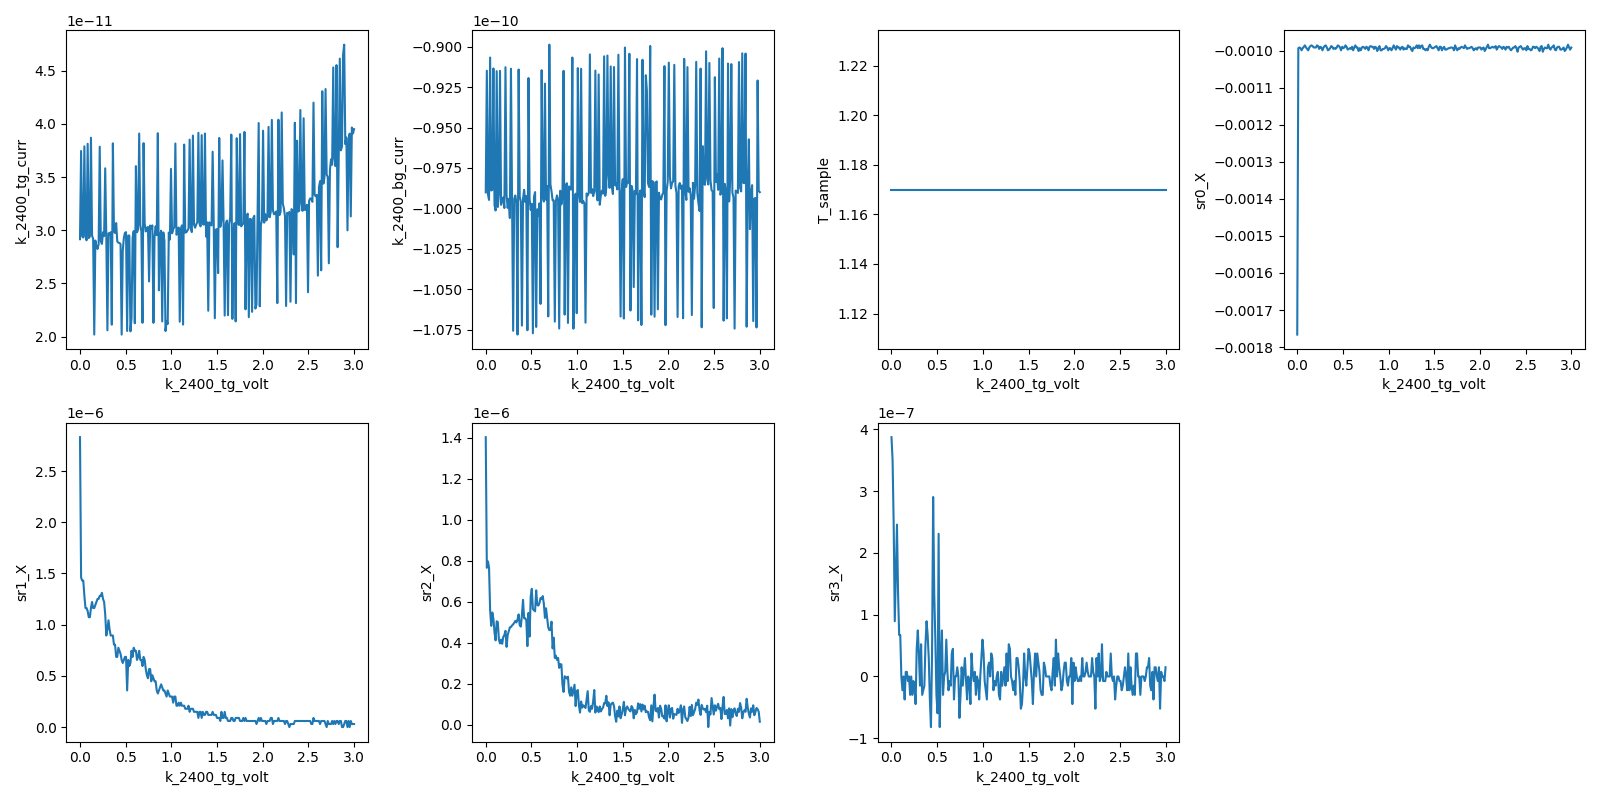

2026-07-17 18:49:57,543 [INFO] Completed in 0h 8m 54s


2026-07-17 18:49:57,544 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\0\data.tsv.gz


2026-07-17 18:49:58,051 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


2026-07-17 18:50:02,346 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-17 18:50:02,871 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-17 18:50:02,886 [INFO] Starting sweep with ID 1


2026-07-17 18:50:02,887 [INFO] Minimum duration 0h 4m 11s


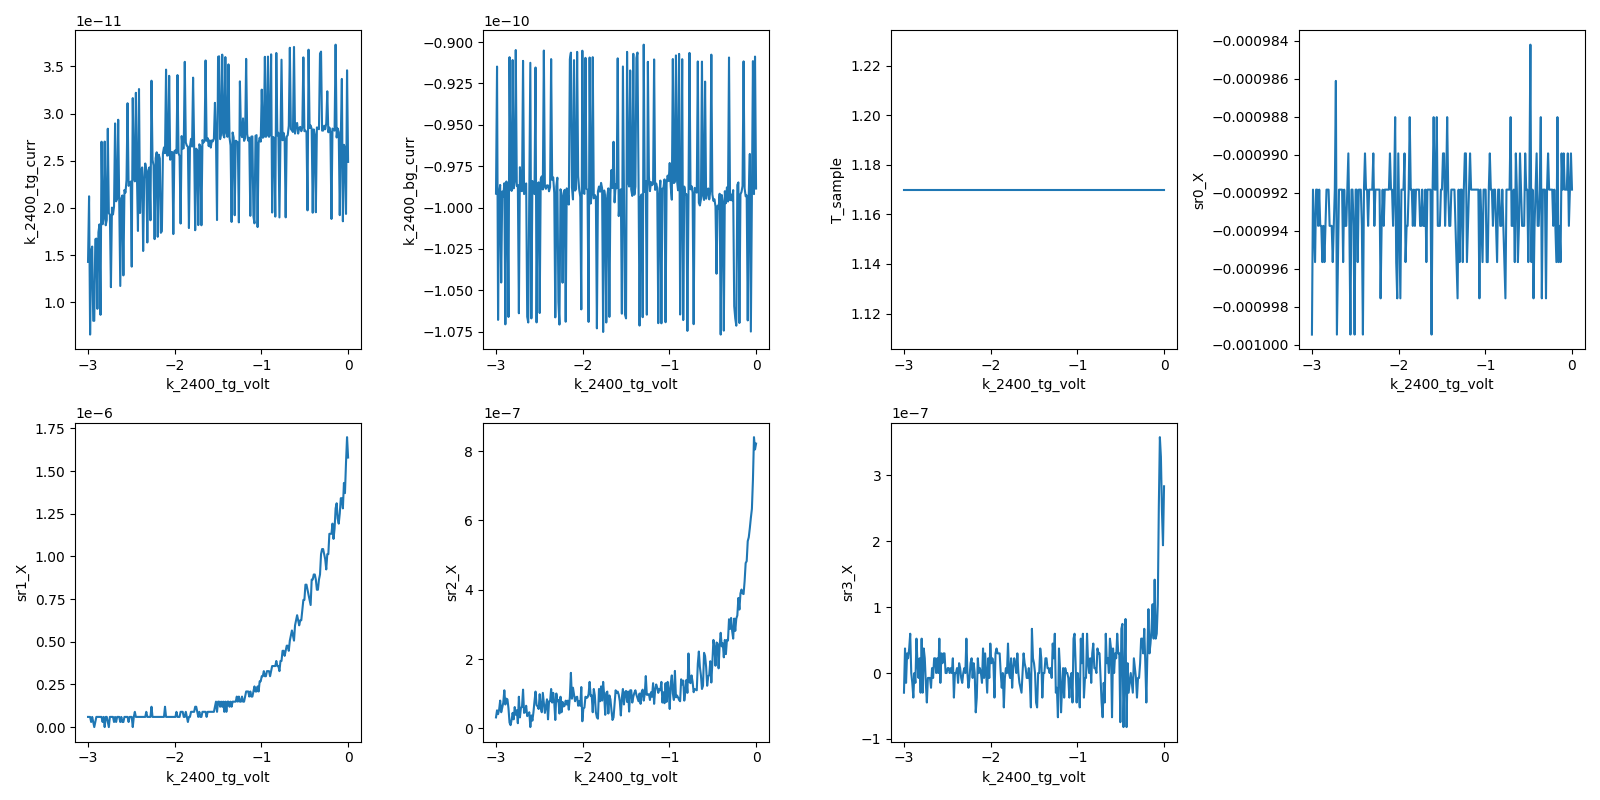

2026-07-17 18:58:54,489 [INFO] Completed in 0h 8m 50s


2026-07-17 18:58:54,490 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\1\data.tsv.gz


2026-07-17 18:58:55,002 [INFO] Ramping k_2400_tg_volt: -3.0 -> 0


2026-07-17 18:58:59,364 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-17 18:58:59,876 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-17 18:58:59,888 [INFO] Starting sweep with ID 2


2026-07-17 18:58:59,889 [INFO] Minimum duration 0h 4m 11s


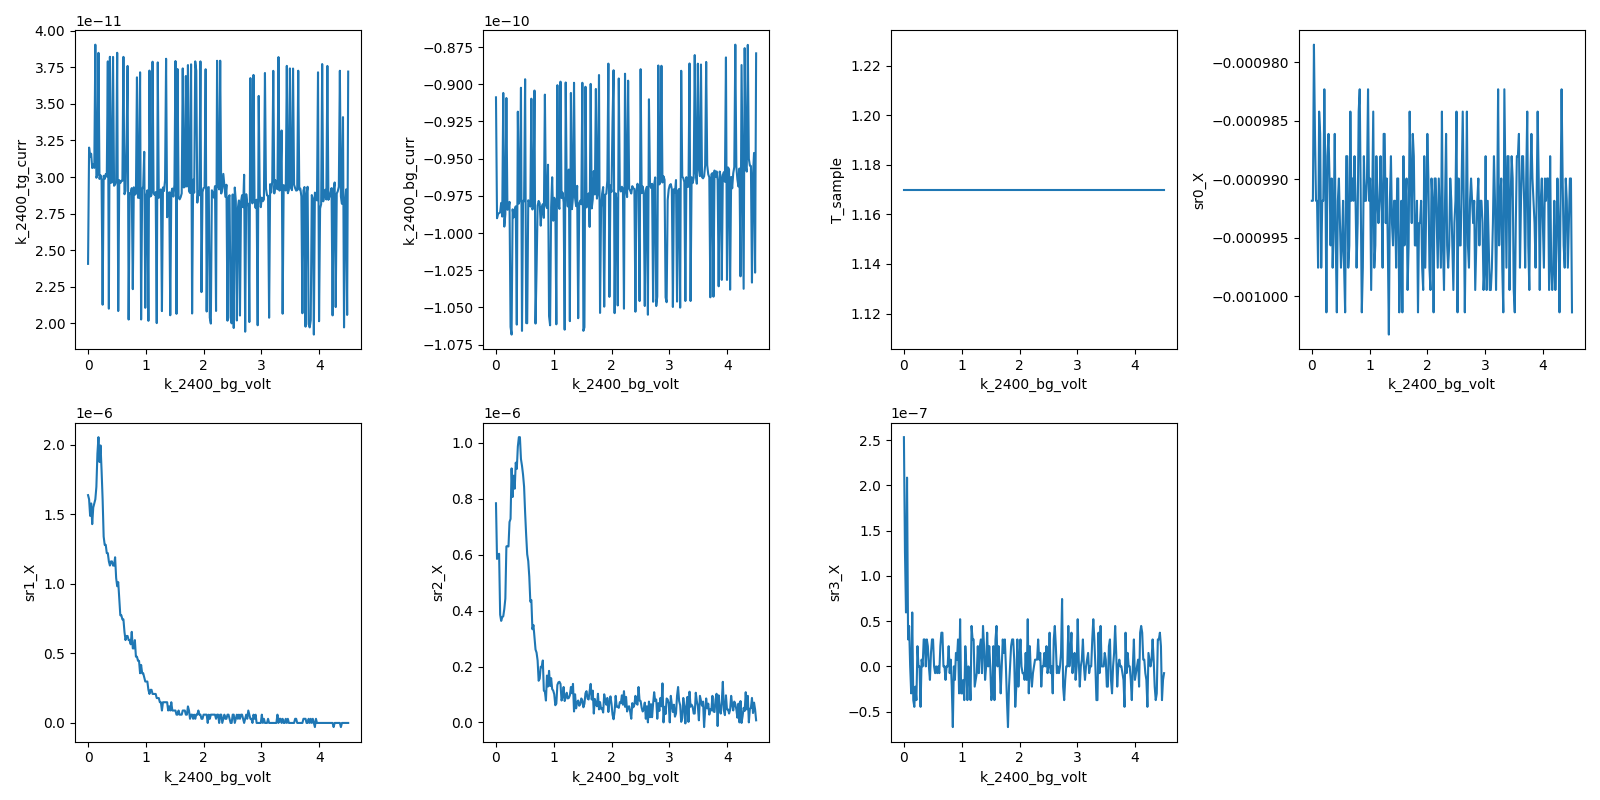

2026-07-17 19:07:55,856 [INFO] Completed in 0h 8m 55s


2026-07-17 19:07:55,856 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\2\data.tsv.gz


2026-07-17 19:07:56,377 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


2026-07-17 19:08:02,558 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-17 19:08:03,073 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-17 19:08:03,083 [INFO] Starting sweep with ID 3


2026-07-17 19:08:03,083 [INFO] Minimum duration 0h 4m 11s


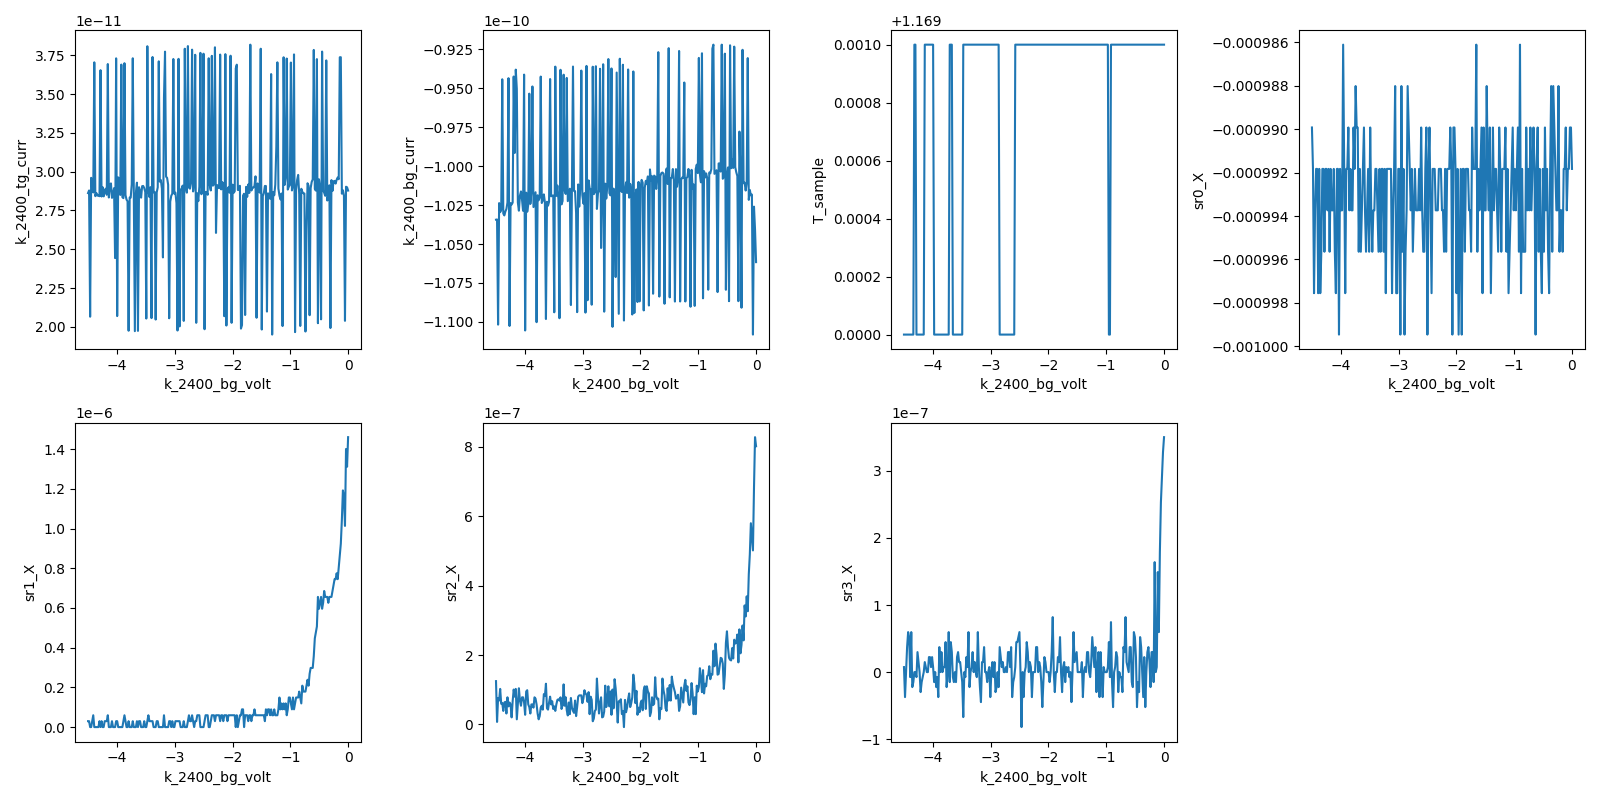

2026-07-17 19:16:59,070 [INFO] Completed in 0h 8m 55s


2026-07-17 19:16:59,071 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\3\data.tsv.gz


2026-07-17 19:16:59,583 [INFO] Ramping k_2400_bg_volt: -4.5 -> 0


gate-current-sanity-check: all legs complete; gates parked at 0


In [19]:
# === Gate C — liveness pass (gate-current-sanity-check), Cell A ===
# Four legs: TG 0->+3, TG 0->-3, BG 0->+4.5, BG 0->-4.5 (card limits from the
# SAFETIES slot; nothing hand-substituted). Other gate parked at 0, Si at 0.
# Per leg: watch swept-gate curr (pA, charging slope = safe), parked-gate curr
# (floor = no cross-gate path), lock-in X (nonzero, smooth = alive).

# -- preconditions (state this cell assumes but does not set)
B = magnet.field()
Ts = T_sample()
print(f"precheck: B={B:+.4f} T (expect ~0), T_sample={Ts:.3f} K (expect ~1.2)")
assert abs(B) < 0.05, f"STOP: field not at zero: {B} T"
assert Ts < 1.5, f"STOP: sample not at base: {Ts} K"

# -- bring-up record: lock-in settling + drive state (run-metadata snapshots
#    store tau/slope as None — this printout is where tau lives on disk)
for lia in (sr0, sr1, sr2, sr3):
    print(f"{lia.name}: tau={lia.time_constant()} s, slope={lia.filter_slope()} dB/oct, "
          f"sens={lia.sensitivity()} V")
print(f"sr1 drive: amplitude={sr1.amplitude()} V, freq={sr1.frequency():.2f} Hz")
print(f"rangei: k_tg={k_2400_tg.rangei()}, k_bg={k_2400_bg.rangei()}")

# liveness drive ~1 nA: 0.1 V into the 100 MOhm bias resistor (device card
# drive->current relation); don't inherit the residual amplitude
sr1.amplitude(0.1)

# pA-floor gate-current readback; the follow-up cell resets to 1
k_2400_tg.nplci(10)
k_2400_bg.nplci(10)

legs = [
    (k_2400_tg, TG_MAX), (k_2400_tg, TG_MIN),
    (k_2400_bg, BG_MAX), (k_2400_bg, BG_MIN),
]
n_pts = 251
delay = 1  # s >= 4*tau = 1.2 s effective with read time (device-card dwell floor)

for gate, v_end in legs:
    meas_config["comments"] = (
        f"gate-current-sanity-check: {gate.name} 0 -> {v_end:+g} V (card limit), "
        f"other gate parked 0, Si 0; drive 0.1 V / 100 MOhm ~1 nA, 13 Hz"
    )
    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}')
    s.add_comment(f'leg: 0 -> {v_end:+g} V (card limit)')

    # park both gates at 0 (swept one starts from 0)
    s.ramp(k_2400_tg.volt, 0)
    s.ramp(k_2400_bg.volt, 0)

    xp = gate.volt
    s.fp(k_2400_tg.volt).fp(k_2400_tg.curr)
    s.fp(k_2400_bg.volt).fp(k_2400_bg.curr)
    s.fp(T_sample)
    s.plot(xp, k_2400_tg.curr)
    s.plot(xp, k_2400_bg.curr)
    s.plot(xp, T_sample)
    for lia in (sr0, sr1, sr2, sr3):
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X)

    try:
        s.sweep(gate.volt, np.linspace(0, v_end, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)

print("gate-current-sanity-check: all legs complete; gates parked at 0")


## HERA — gate C Cell B: reset nplci

All four legs ran clean (runs 0–3: |I_gate| ≤ 47 pA on the swept gate everywhere, parked-gate at its ~100 pA readback offset, no turn-up, no interrupts; device passes the full ~1 nA drive and both gates modulate the channel). Resetting the pA-readback nplci bump per the recipe; validators stay as committed.

In [20]:
# === Reset gate-current nplci (gate-current-sanity-check Cell B) ===
k_2400_tg.nplci(1)
k_2400_bg.nplci(1)
print('k_tg.volt validator:', k_2400_tg.volt.vals)
print('k_bg.volt validator:', k_2400_bg.volt.vals)

k_tg.volt validator: <Numbers -3.0<=v<=3.0>
k_bg.volt validator: <Numbers -4.5<=v<=4.5>


## HERA — 0 T gate map (`gatemap`), investigation step 1

Gate C passed (runs 0–3 clean; ana notebook has the verdict). Next per
`trilayer-stacking-fs-count` step 1: the cooldown's first 0 T (V_tg, V_bg)
map, raw gate voltages (cap ratios not yet trusted), full validator box —
**TG fast [−3, +3] 101 pts (60 mV) × BG slow [−4.5, +4.5] 101 rows (90 mV)**,
Si at 0 V. Gate C puts the CNP near (0,0) with R ~ 1–3 kΩ, so the geometry
prior (slope −1.3) predicts the CNP ridge crossing the TG window for
|V_bg| ≲ 2.3 V — comfortably inside this box; the box's D-span also buys the
CNP-vs-D read (gap systematics) for free.

**Settings**: 5 nA bias (0.5 V/100 MΩ, card starting point); sens sr1–sr3
2×10⁻⁴ (R ceiling 40 kΩ at 5 nA — headroom for a D-gapped CNP; a railed
ridge row is handled by the calibration recipe's robust-fit guard), sr0
10 mV. **Settling**: fast_delay 1 s + ~0.35 s reads ≈ 1.35 s/pt = 4.5·τ —
the device card's stated 4τ dwell floor, below the rig card's conservative
7–10·τ; accepted knowingly for broad CNP-ridge extraction (≲2% settling
error, irrelevant to ridge position).

**Cost**: 101 × (101 × ~1.35 s + 7 s flyback + 3 s) ≈ **4.2 h** (from gate C
measured overhead, runs 0–3: predicted read time confirmed at NPLC=10;
NPLC=1 scales reads to ~0.35 s/pt). Headline 4.2–4.6 h.

**Checkpoints**: first rows (railing / dead channel / leakage), then every
~15 rows via the armed watch — interim CNP-ridge read as rows accumulate;
abort criteria: gate current off the pA floor toward nA, all-channel flat
(grounding), or T excursion. E1 auto bucket: endpoints = validator limits,
preconditions asserted in-cell.


precheck: B=+0.0034 T (expect ~0), T_sample=1.169 K (expect ~1.2)


drive 0.5 V -> 5 nA; sens sr1/sr2/sr3 = 2e-4, sr0 = 1e-2
2026-07-17 19:21:59,596 [INFO] Ramping k_2400_tg_volt: 0.0 -> -3.0


2026-07-17 19:22:03,492 [INFO] Ramping k_2400_bg_volt: 0.0 -> -4.5


2026-07-17 19:22:19,231 [INFO] Starting megasweep with ID 4


2026-07-17 19:22:19,232 [INFO] Minimum duration 2h 55m 4s


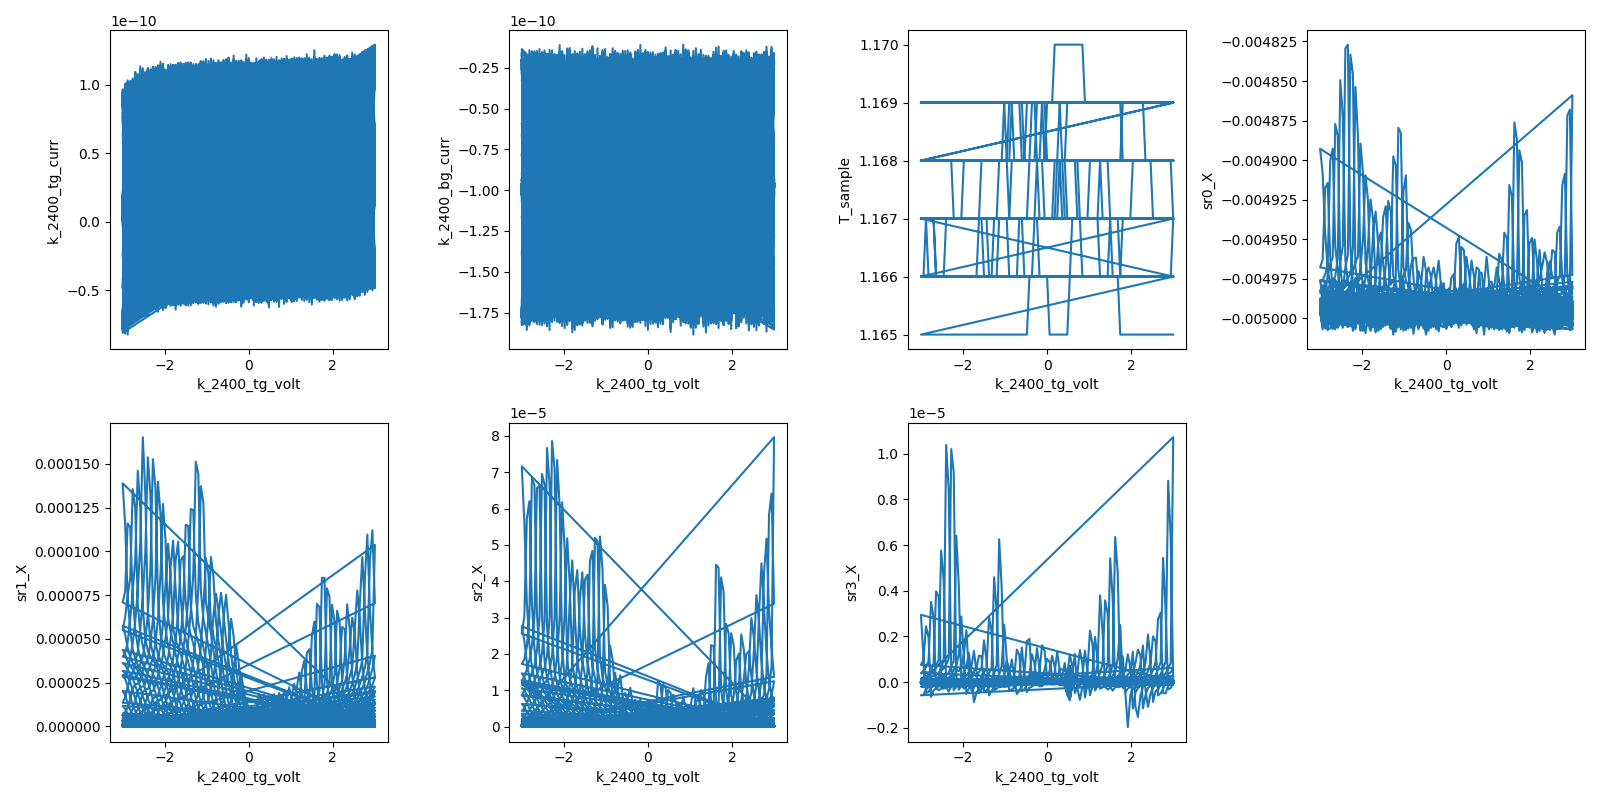

2026-07-17 23:11:00,751 [INFO] Completed in 3h 48m 40s


2026-07-17 23:11:00,751 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\4\data.tsv.gz


2026-07-17 23:11:00,810 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


2026-07-17 23:11:04,664 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


gatemap complete; gates parked at 0


In [21]:
# === 0 T gate map (gatemap): full validator box, 101x101 ===
# BG slow -4.5 -> +4.5 (101 rows), TG fast -3 -> +3 (101 pts, 60 mV steps).
# Feeds cnp-and-dline-calibration (investigation step 1).

# -- preconditions (assumed, not set by this cell)
B = magnet.field()
Ts = T_sample()
print(f"precheck: B={B:+.4f} T (expect ~0), T_sample={Ts:.3f} K (expect ~1.2)")
assert abs(B) < 0.05, f"STOP: field not at zero: {B} T"
assert Ts < 1.5, f"STOP: sample not at base: {Ts} K"

# -- drive + sensitivities for the CNP-scale map (device-card starting points,
#    tuned to what gate C measured: R ~ 1-3 kOhm near (0,0), tens of Ohm metallic)
sr1.amplitude(0.5)          # 0.5 V / 100 MOhm = 5 nA bias
for lia in (sr1, sr2, sr3):
    lia.sensitivity(2e-4)   # ceiling R = 2e-4/5nA = 40 kOhm; quantization ~1.2 Ohm
sr0.sensitivity(1e-2)       # drain: 5 nA x 1e6 V/A = 5 mV signal on 10 mV sens
print(f"drive {sr1.amplitude()} V -> 5 nA; sens sr1/sr2/sr3 = 2e-4, sr0 = 1e-2")

meas_config["comments"] = (
    "gatemap: 0 T, TG fast [-3,+3] 101 pts x BG slow [-4.5,+4.5] 101 rows, "
    "Si 0 V; drive 0.5 V / 100 MOhm = 5 nA @ 13 Hz; fast_delay 1 s, slow_delay 3 s"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('first map of cooldown: full validator box, feeds cnp-and-dline-calibration')

# park at start corner and settle
s.ramp(k_2400_tg.volt, -3.0)
s.ramp(k_2400_bg.volt, -4.5)
interruptible_sleep(10)

xp = k_2400_tg.volt
s.fp(k_2400_tg.volt).fp(k_2400_tg.curr)
s.fp(k_2400_bg.volt).fp(k_2400_bg.curr)
s.fp(T_sample)
s.plot(xp, k_2400_tg.curr)
s.plot(xp, k_2400_bg.curr)
s.plot(xp, T_sample)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)

try:
    s.megasweep(
        k_2400_bg.volt, np.linspace(-4.5, 4.5, 101),
        k_2400_tg.volt, np.linspace(-3.0, 3.0, 101),
        slow_delay=3, fast_delay=1,
    )
finally:
    s.ramp(k_2400_tg.volt, 0)
    s.ramp(k_2400_bg.volt, 0)

print("gatemap complete; gates parked at 0")


## HERA — calibration commit (cnp-and-dline-calibration, run 4)

Gatemap run 4 analyzed (ana cells 13–16; contract written to device_card.md). Committing the session (n, D) conversion into this kernel for sweep design: ratio **data-calibrated** (c_bg/c_tg = 1.2863, channels agree 0.5%, geometry −1.1%), absolute scale **geometry prior** (QH lever-arm upgrade pending), N_OFFSET −0.052e12 cm⁻², D_OFFSET 0 (R_CNP minimum at V_bg ≈ 0 — cited feature). No instrument writes in this cell.

In [22]:
# Session (n, D) calibration — from run 4 (cnp-and-dline-calibration)
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages
C_TG = stack_capacitance([(15.6, 3)])   # F/m^2 — geometry-prior anchor
RATIO_CAL = 1.2863                      # c_bg/c_tg, data-calibrated (run 4)
C_BG = C_TG * RATIO_CAL
N_OFFSET = -0.0523                      # e12 cm^-2 (run 4 intercept +0.0492 V)
D_OFFSET = 0.0                          # V/nm (R_CNP min at V_bg ~ 0, run 4)
def gates_for(n, D=0.0):
    '''(V_tg, V_bg) for n [e12 cm^-2], D [V/nm] under the session calibration.'''
    return calc_gate_voltages(n, D, C_TG, C_BG, n_offset=N_OFFSET, D_offset=D_OFFSET)
for n in (-3.0, +3.0):
    vt, vb = gates_for(n)
    print(f'n={n:+.1f}e12, D=0 -> Vtg={vt:+.4f} V, Vbg={vb:+.4f} V')
print('F_L(3.0e12) = %.2f T' % (6.62607015e-34/(4*1.602176634e-19)*3.0e16))

n=-3.0e12, D=0 -> Vtg=-1.3868 V, Vbg=-1.0781 V
n=+3.0e12, D=0 -> Vtg=+1.4360 V, Vbg=+1.1164 V
F_L(3.0e12) = 31.02 T


## HERA — SdH spot check H: hole side, n = −3.0×10¹² cm⁻², D = 0 (`sdh-spot-check`)

Investigation steps 2–3. Design from the run-4 calibration: gates
(−1.387, −1.078) V via the committed conversion; **F_L = 31.0 T** at
|n| = 3.0e12 (kept under the FS-model's 3.5e12 overlay clamp);
**uniform-B grid** (blocking rate-limited magnet): ΔB = Δ(1/B)·B_lo² =
**5.26 mT** (⅓-Nyquist on F_L at B_lo = 0.7 T), 1389 pts, **0.7 → 8 T
ascending** (magnet sits at 0 — never re-traverse; the electron check will
descend 8 → 0.7 next, ending low for the fan). Expected onset ~0.5–1 T
(T_e ≈ 8 K rig); B_lo sits below it and the low-B edge reads the onset.
δF ≈ 1.1 T if onset ≈ 1 T — separates an ABA pair partner from F_L for ML
fractions ≳ 7%.

**Settings**: 20 nA bias (2 V/100 MΩ, card high-|n| point); sens sr1–sr3
5×10⁻⁵ (Rxx ceiling 2.5 kΩ, R_xy(8 T) ≈ 1.7 kΩ inside range; quantization
0.08 Ω — no grainy-FFT digitization), sr0 50 mV. **Dwell**: `settle_s`
1.2 s (= 4τ card floor) replaces the 3 s default as the post-step dwell,
`delay=0` — the 5 mT step ramp (~2.3 s) + 1.2 s settle + reads ≈ 3.9 s/pt.
Stated bend: settle_s is a dwell knob, not a safety surface; 3 s default
would add ~40 min for nothing at this step size.

**Cost**: 5 min ramp-in + 1389 × ~3.9 s ≈ **95–105 min**. Checkpoints:
first ~50 pts (sens railing / leakage at 20 nA / T stability), then
periodic via hera-watch; abort on railing (retune sens, restart — cheap
early), leakage off pA floor, or T runaway. E1 auto: gates and B inside
committed validators, preconditions asserted.


precheck: B=+0.0034 T (expect ~0), T=1.165 K


drive 2.0 V -> 20 nA; sens sr1/2/3 = 5e-5, sr0 = 5e-2
gates: Vtg=-1.3868, Vbg=-1.0781
grid: 1387 pts, dB=5.27 mT, uniform B ascending
2026-07-17 23:18:05,606 [INFO] Ramping k_2400_tg_volt: 0.0 -> -1.386814242719977


2026-07-17 23:18:07,431 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.0781421462489131


2026-07-17 23:18:08,796 [INFO] Ramping magnet_field: 0.003400191780821918 -> 0.7


2026-07-17 23:23:26,500 [INFO] Starting sweep with ID 5


2026-07-17 23:23:26,504 [INFO] Minimum duration 0h 0m 0s


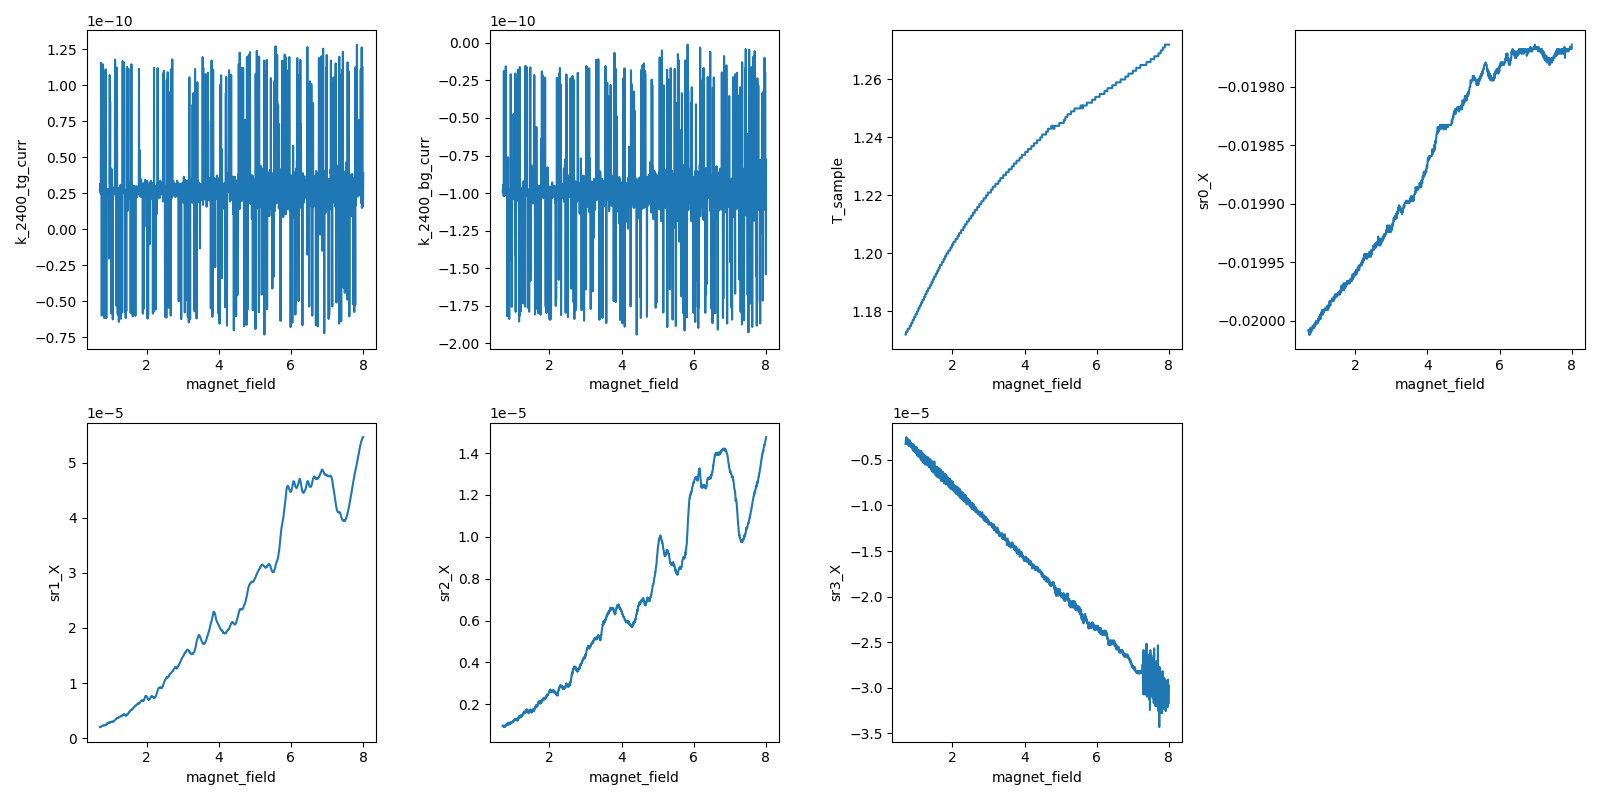

2026-07-18 00:48:35,359 [INFO] Completed in 1h 25m 8s


2026-07-18 00:48:35,360 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\5\data.tsv.gz


spot check H done; B at +8.005 T (stay for cell E)


In [23]:
# === SdH spot check H — hole side: n = -3.0e12, D = 0; B 0.7 -> 8 T ===
# Blocking rate-limited magnet -> uniform-B grid, Nyquist held at the low-B edge
# (sdh-spot-check recipe step 1b). Design numbers (step 2):
#   F_L = (h/4e)*3.0e16 = 31.0 T ;  D(1/B) = 1/(3 F_L) = 0.01074 1/T
#   dB = D(1/B) * B_lo^2 = 0.01074 * 0.49 = 5.26 mT ;  N = 1389
#   dF resolution (step 3): assuming onset ~1 T: dF = 1/(1/1 - 1/8) = 1.14 T
#     -> separates f_BL from F_L when ML fraction > ~7%; ABA small tone f_ML
#        at a few T resolvable against 0.

# -- preconditions (assumed, not set)
B = magnet.field()
Ts = T_sample()
print(f"precheck: B={B:+.4f} T (expect ~0), T={Ts:.3f} K")
assert abs(B) < 0.05, f"STOP: field not near zero: {B} T"
assert Ts < 1.5, f"STOP: not at base T: {Ts} K"

# -- drive & sensitivities (high-|n| metallic regime, device card + run-4 scales)
sr1.amplitude(2.0)   # 2 V / 100 MOhm = 20 nA bias
sr1.sensitivity(5e-5)   # Rxx ceiling 2.5 kOhm @ 20 nA; quantization ~0.08 Ohm
sr2.sensitivity(5e-5)
sr3.sensitivity(5e-5)   # Rxy(8 T, 3e12) = B/ne ~ 1.67 kOhm < 2.5 kOhm ceiling
sr0.sensitivity(5e-2)   # drain 20 nA x 1e6 = 20 mV
print(f"drive {sr1.amplitude()} V -> 20 nA; sens sr1/2/3 = 5e-5, sr0 = 5e-2")

# -- field-step dwell: settle_s = 1.2 s (= 4*tau lock-in floor; default 3 s is
#    a flat dwell on top of the ramp — 1.2 s serves both field settle and
#    filter settle after a 5 mT step). Stated bend, not a safety surface.
magnet.settle_s = 1.2

# -- gates to (n, D) = (-3.0e12, 0)
vtg_h, vbg_h = gates_for(-3.0, 0.0)
print(f"gates: Vtg={vtg_h:+.4f}, Vbg={vbg_h:+.4f}")

F_L = 31.02
d_invB = 1.0 / (3 * F_L)
B_LO, B_HI = 0.7, 8.0
dB = d_invB * B_LO**2
NPTS = int(np.floor((B_HI - B_LO) / dB)) + 1
B_vec = np.linspace(B_LO, B_HI, NPTS)
print(f"grid: {NPTS} pts, dB={dB*1e3:.2f} mT, uniform B ascending")

meas_config["comments"] = (
    "sdh-spot-check: hole side n=-3.0e12 cm^-2, D=0 "
    f"(Vtg={vtg_h:+.3f}, Vbg={vbg_h:+.3f}); B 0.7->8 T uniform, dB=5.26 mT "
    "(1/3-Nyquist on F_L=31 T at B_lo); 20 nA bias @ 13 Hz; settle_s=1.2"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'(Vtg, Vbg) = ({vtg_h:.4f}, {vbg_h:.4f}), n = -3.0, D = 0')

s.ramp(k_2400_tg.volt, vtg_h)
s.ramp(k_2400_bg.volt, vbg_h)
s.ramp(magnet.field, B_LO)   # blocking ramp ~5 min from 0
interruptible_sleep(10)

s.fp(magnet.field)
s.fp(k_2400_tg.volt).fp(k_2400_tg.curr)
s.fp(k_2400_bg.volt).fp(k_2400_bg.curr)
s.fp(T_sample)
s.plot(magnet.field, k_2400_tg.curr)
s.plot(magnet.field, k_2400_bg.curr)
s.plot(magnet.field, T_sample)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)

s.sweep(magnet.field, B_vec, delay=0)   # settle_s provides the post-step dwell
print(f"spot check H done; B at {magnet.field():+.3f} T (stay for cell E)")


## HERA — SdH spot check E: electron side, n = +3.0×10¹² cm⁻², D = 0 (`sdh-spot-check`)

Run 5 (hole) read: onset 0.77 T; dominant slow tone ~4.4–5.5 T + harmonic
train; weak 23–28 T content; small ~32 T peak (sr2). ABA-pair template
(f_ML ≈ 5, f_BL ≈ 26, sum = F_L) vs harmonic-train confound — n-dependence
and the electron side discriminate (recipe: electron-side ML tone grows with
|n|; both sides get a check). Full analysis landing in ana nb.

This cell: same 1387-pt uniform grid **descending 8 → 0.7 T** (magnet sits
at 8 T — never re-traverse; ends low, fan-ready). Gates switch at 8 T to
(+1.436, +1.116) V. One sens change from H's near-rail: **sr1 → 1×10⁻⁴**
(5 kΩ ceiling; H topped 2.73 kΩ). Cost ≈ **90 min** (run-5 measured
16.3 rows/min). Checkpoints as run 5. E1 auto.


precheck: B=+8.003 T (expect ~8), T=1.273 K


sens: sr1 0.0001, sr2 5e-05, sr3 5e-05
gates: Vtg=+1.4360, Vbg=+1.1164
grid: 1387 pts, dB=5.27 mT, uniform B descending
2026-07-18 00:50:18,663 [INFO] Ramping k_2400_tg_volt: -1.387 -> 1.4360257533175644


2026-07-18 00:50:22,302 [INFO] Ramping k_2400_bg_volt: -1.078 -> 1.1164003368713087


2026-07-18 00:50:35,089 [INFO] Starting sweep with ID 6


2026-07-18 00:50:35,090 [INFO] Minimum duration 0h 0m 0s


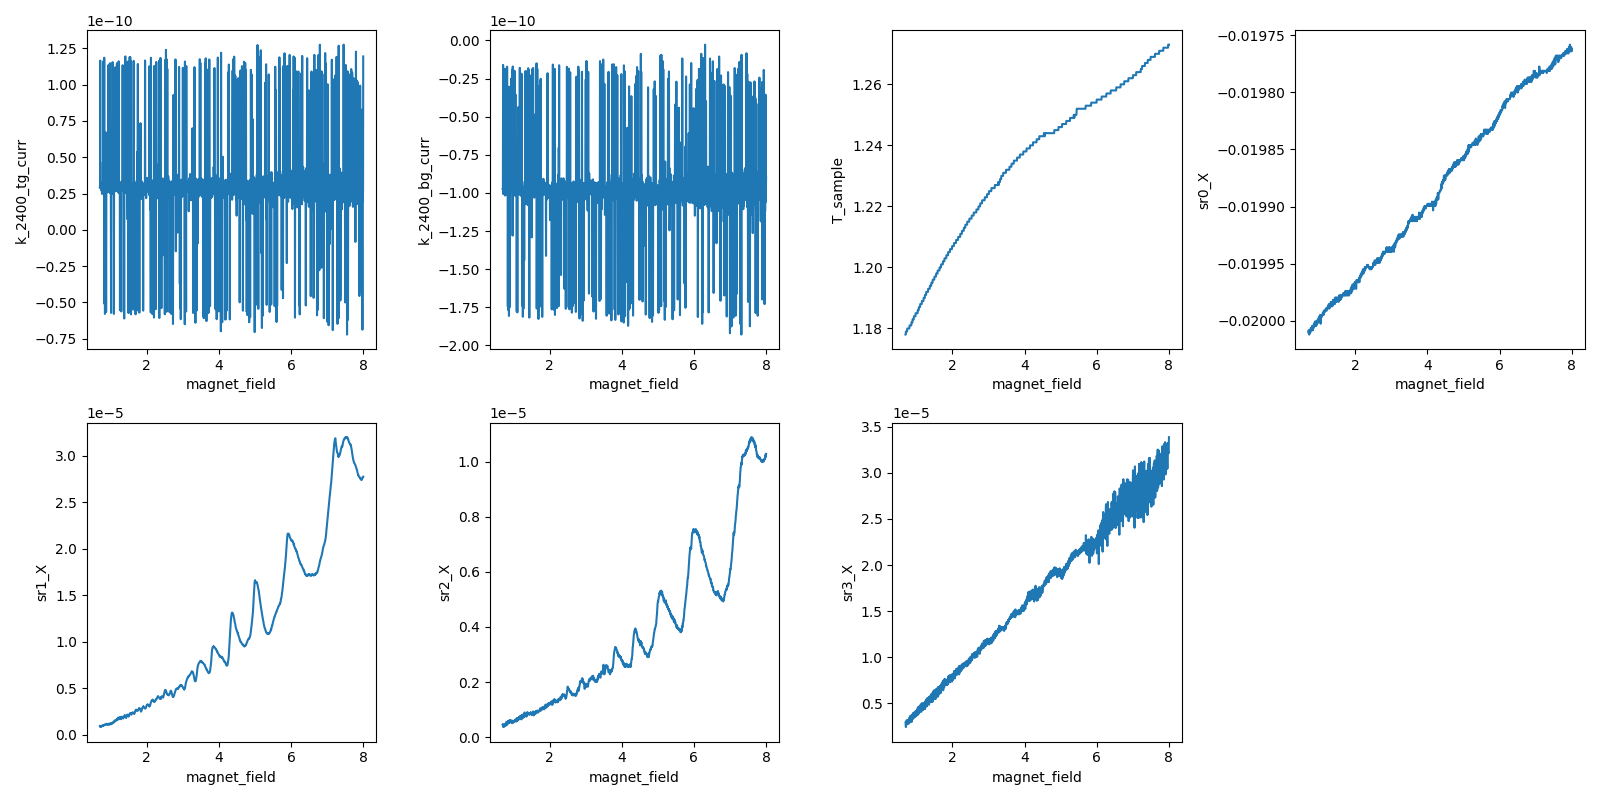

2026-07-18 02:15:39,102 [INFO] Completed in 1h 25m 3s


2026-07-18 02:15:39,104 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\6\data.tsv.gz


spot check E done; B at +0.702 T (low — fan-ready)


In [24]:
# === SdH spot check E — electron side: n = +3.0e12, D = 0; B 8 -> 0.7 T ===
# Same grid as run 5 reversed (never re-traverse; ends low for the fan).
# Sens change from H's read: sr1 -> 1e-4 (H hit 2.73 kOhm at 8 T, ~109% of
# the 2.5 kOhm nominal ceiling; descending hits high B first).

# -- preconditions (assumed, not set)
B = magnet.field()
Ts = T_sample()
print(f"precheck: B={B:+.3f} T (expect ~8), T={Ts:.3f} K")
assert abs(B - 8.0) < 0.1, f"STOP: field not at 8 T: {B} T"
assert Ts < 1.5, f"STOP: not at base T: {Ts} K"

sr1.sensitivity(1e-4)   # Rxx ceiling 5 kOhm @ 20 nA (H topped 2.73 kOhm)
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}")

vtg_e, vbg_e = gates_for(+3.0, 0.0)
print(f"gates: Vtg={vtg_e:+.4f}, Vbg={vbg_e:+.4f}")

F_L = 31.02
d_invB = 1.0 / (3 * F_L)
B_LO, B_HI = 0.7, 8.0
dB = d_invB * B_LO**2
NPTS = int(np.floor((B_HI - B_LO) / dB)) + 1
B_vec = np.linspace(B_HI, B_LO, NPTS)   # descending
print(f"grid: {NPTS} pts, dB={dB*1e3:.2f} mT, uniform B descending")

meas_config["comments"] = (
    "sdh-spot-check: electron side n=+3.0e12 cm^-2, D=0 "
    f"(Vtg={vtg_e:+.3f}, Vbg={vbg_e:+.3f}); B 8->0.7 T uniform, dB=5.26 mT "
    "(1/3-Nyquist on F_L=31 T at B_lo); 20 nA bias @ 13 Hz; settle_s=1.2; "
    "sr1 sens 1e-4 after run-5 near-rail"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'(Vtg, Vbg) = ({vtg_e:.4f}, {vbg_e:.4f}), n = +3.0, D = 0')

# gate switch at 8 T: hole point -> electron point through CNP, paced by
# volt.step (5 mV); stays inside validators the whole path
s.ramp(k_2400_tg.volt, vtg_e)
s.ramp(k_2400_bg.volt, vbg_e)
interruptible_sleep(10)

s.fp(magnet.field)
s.fp(k_2400_tg.volt).fp(k_2400_tg.curr)
s.fp(k_2400_bg.volt).fp(k_2400_bg.curr)
s.fp(T_sample)
s.plot(magnet.field, k_2400_tg.curr)
s.plot(magnet.field, k_2400_bg.curr)
s.plot(magnet.field, T_sample)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)

s.sweep(magnet.field, B_vec, delay=0)
print(f"spot check E done; B at {magnet.field():+.3f} T (low — fan-ready)")


## HERA — Landau fan, hole side, D = 0 (`landau-fan-vti`), investigation step 4

Spot checks read (ana nb): hole = pair template {~4 T ML, ~27–28 T BL} + a
~33 T tone at F_L; electron = bright singleton 33.2 T fixing the global
scale λ ≈ 1.07; forks: harmonic-vs-BL in the 23–28 T band, and the
F_L-tone origin (breakdown | ABC domain | mixing). **Fan side = hole**:
earliest onset (0.77 T, measured), both pair members + the F_L tone live
there — the combinatorics and the Luttinger partition F(n) need exactly
that. The electron singleton is already characterized for the overlay.

**Floored design (single fan):**
- **B**: 0.77 → 8 T (B_lo = `sdh_onset` measured, not eyeballed), uniform
  1/B (`field_invB`), **141 rows**; Δ(1/B) = 8.33×10⁻³ T⁻¹ = ⅓-Nyquist on
  40 T (covers the λ-scaled supra tone at n_max). δF = 0.85 T.
- **n**: −0.5 → −3.5×10¹² cm⁻² (n_max = overlay-validity clamp; low-|n|
  floor at 0.5 — below it F_L < 5 T merges with the ML band and the
  low-n × high-B corner blows the dynamic range), **101 columns**,
  Δn = 0.03×10¹² ≥ 2 pts/ray for B ≥ 0.86 T.
- **Sens (worst corner −0.5e12 × 8 T)**: sr1 5×10⁻⁴ (25 kΩ), sr2 2×10⁻⁴
  (10 kΩ), sr3 5×10⁻⁴ (|R_xy|max 10 kΩ). Trade: 0.76 Ω quantization on sr1
  at the metallic corner — sr2 (0.3 Ω) is the fine-grain FFT channel there.
- **Direction**: ascending from 0.77 T (magnet sits at 0.70 — no
  re-traverse); ends at 8 T for the high-field/Středa read and any LK
  descent to follow.

**Cost**: 141 × (101 × ~1.45 s + ~4 s row overhead) + 53 min traverse ≈
**6.8 h** (per-point from runs 5/6 measured 16.3 rows/min at same fp set;
headline 6.8–7.5 h). Checkpoints: first rows, then every ~10 rows
(hera-watch); abort criteria: railing at the low-|n| corner, leakage off
floor, T excursion, all-flat channel. E1 auto: axes inside validators
(asserted in-cell), B cap respected by the grid.


precheck: B=+0.703 T (expect ~0.7), T=1.176 K


sens: sr1 0.0005, sr2 0.0002, sr3 0.0005; drive 2.0 V (20 nA)
n-line: Vtg -0.211..-1.622, Vbg -0.164..-1.261
B rows: 141 from 0.770 to 8.000 T
2026-07-18 02:20:04,342 [INFO] Ramping k_2400_tg_volt: 1.436 -> -0.21063091103766787


2026-07-18 02:20:06,481 [INFO] Ramping k_2400_bg_volt: 1.1165 -> -0.16374944494882054


2026-07-18 02:20:18,099 [INFO] Starting multimegasweep with ID 7


2026-07-18 02:20:18,100 [INFO] Minimum duration 3h 59m 42s


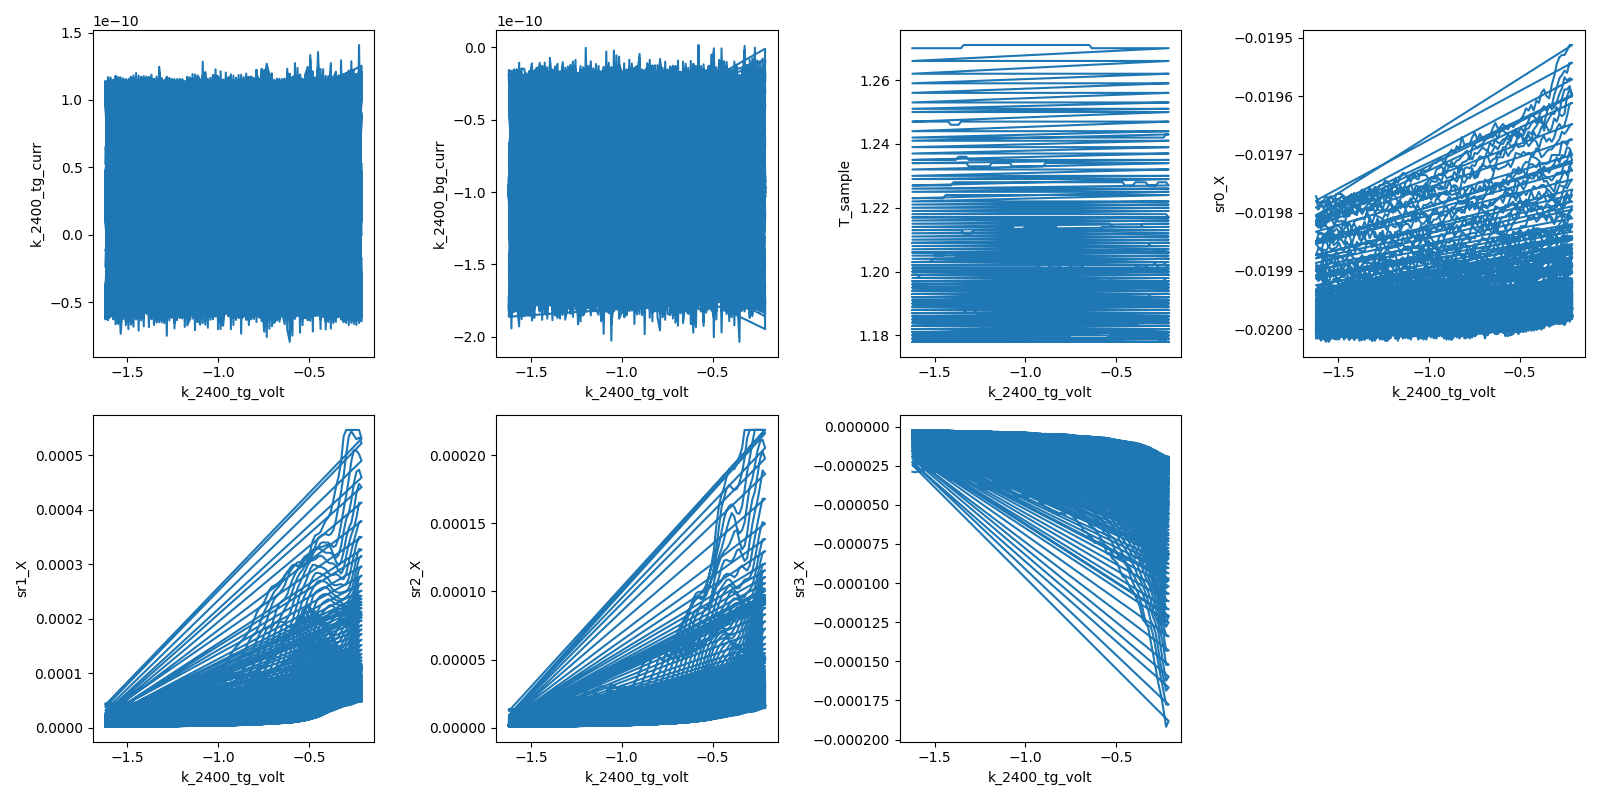

2026-07-18 08:10:23,061 [INFO] Completed in 5h 50m 3s


2026-07-18 08:10:23,065 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\7\data.tsv.gz


2026-07-18 08:10:23,125 [INFO] Ramping k_2400_tg_volt: -1.622 -> 0


2026-07-18 08:10:25,261 [INFO] Ramping k_2400_bg_volt: -1.261 -> 0


fan complete; B at +8.003 T; gates parked at 0


In [25]:
# === Landau fan (landau-fan-vti): hole side, D = 0, per-column SdH-FFT design ===
# n: -0.5 -> -3.5e12 cm^-2 (101 columns; clamp 3.5e12 = model overlay validity)
# B: 0.77 -> 8 T uniform in 1/B (field_invB), 141 rows
#   D(1/B) = 8.33e-3 1/T = 1/(3*40 T) — 1/3-Nyquist on the lambda-scaled
#   supra tone at n_max (F_L*1.07 at 3.5e12 ~ 38.7 T). Harmonics >60 T alias
#   to >43 T — outside the 0-40 T claim band (noted).
# n-axis: dn = 0.03e12 >= 2 pts/ray for B >= 0.86 T (ray Nyquist).
# delta_F = 1/(1/0.77 - 1/8) = 0.85 T — separates 27 vs 33 (>> 2*delta_F).

# -- preconditions (assumed, not set)
B = magnet.field()
Ts = T_sample()
print(f"precheck: B={B:+.3f} T (expect ~0.7), T={Ts:.3f} K")
assert abs(B - 0.7) < 0.15, f"STOP: field not at ~0.7 T: {B} T"
assert Ts < 1.5, f"STOP: not at base T: {Ts} K"

# -- sensitivities sized at the global worst corner (n=-0.5e12 x 8 T):
#    sr1 R(worst) ~ 16-20 kOhm -> 5e-4 (25 kOhm ceiling @ 20 nA)
#    sr2 ~ 2.5x lower R -> 2e-4 (10 kOhm); sr3 |Rxy|max = 8/(0.5e16 e) = 10 kOhm -> 5e-4
sr1.sensitivity(5e-4)
sr2.sensitivity(2e-4)
sr3.sensitivity(5e-4)
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}; "
      f"drive {sr1.amplitude()} V (20 nA)")

# -- axes
ns = np.linspace(-0.5, -3.5, 101)          # e12 cm^-2
Vtgs, Vbgs = gates_for(ns, 0.0)
assert np.all(np.abs(Vtgs) <= 3.0) and np.all(np.abs(Vbgs) <= 4.5), "n-line exits validators"
print(f"n-line: Vtg {Vtgs[0]:+.3f}..{Vtgs[-1]:+.3f}, Vbg {Vbgs[0]:+.3f}..{Vbgs[-1]:+.3f}")

B_vec = field_invB(0.77, 8.0, 141)         # uniform in 1/B, ascending
print(f"B rows: {len(B_vec)} from {B_vec[0]:.3f} to {B_vec[-1]:.3f} T")

meas_config["comments"] = (
    "landau-fan-vti: hole side, D=0, n -0.5..-3.5e12 (101 cols) x B 0.77..8 T "
    "(141 rows, uniform 1/B, D(1/B)=8.33e-3); 20 nA @ 13 Hz; sens sr1 5e-4 "
    "sr2 2e-4 sr3 5e-4; settle_s=1.2; inherits run-5/6 spot-check design"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment('D = 0 V/nm, n = -0.5 to -3.5 e12 cm^-2, B = 0.77 to 8 T')

s.ramp(k_2400_tg.volt, Vtgs[0])
s.ramp(k_2400_bg.volt, Vbgs[0])
interruptible_sleep(10)

s.fp(magnet.field)
s.fp(k_2400_tg.volt).fp(k_2400_tg.curr)
s.fp(k_2400_bg.volt).fp(k_2400_bg.curr)
s.fp(T_sample)
s.plot(k_2400_tg.volt, k_2400_tg.curr)
s.plot(k_2400_tg.volt, k_2400_bg.curr)
s.plot(k_2400_tg.volt, T_sample)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_2400_tg.volt, lia.X)

try:
    s.multimegasweep([magnet.field], [B_vec],
                     [k_2400_tg.volt, k_2400_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=1)
finally:
    s.ramp(k_2400_tg.volt, 0)
    s.ramp(k_2400_bg.volt, 0)

print(f"fan complete; B at {magnet.field():+.3f} T; gates parked at 0")


## HERA — LK mass ladder (`temperature-dependence-vti`, Flavor B) — the deciding cross-check

Fan verdict so far (ana): hole side shows the ABA template — three-tone
{f_ML, f_BL, ≈λF_L} in 99% of columns, partition f_ML+f_BL = λF_L
(λ = 1.069 Luttinger-pinned), B-window split favors breakdown for the
≈F_L tone. **Per-branch LK masses decide**: expect m*(f_ML) ~ 0.013 mₑ,
m*(f_BL) ~ 0.05–0.07 mₑ, and the F_L tone damping with ≈ m_ML + m_BL if
it is the breakdown sum orbit (an ABC-domain pocket would carry its own
single-band mass). Two distinct masses + a sum-mass = **ABA confirmed**.

**Design**: fixed point = hole spot (n = −3.0e12, D = 0, run-5/6-proven
sens); B 1.5 ↔ 8 T (δF = 1.85 T — resolves the 28/33 split), 288 pts at
ΔB = 22.6 mT (⅓-Nyquist on 33.2 T), alternating direction from live field
per rung. **Rungs ascending** (up-legs catch in 2.5–4 min; descents are
passive-limited): base, 6, 10, 15, 22, 32 K — all ≤ 50 K cap,
`set_both(T, ratio=0.95)` (sanctioned; ratio untouched). Ladder covers
heavy-tone kill (~15–20 K at m* ~ 0.06) with the light tone surviving to
32 K; T_e ≈ 8 K floor noted — masses lean on the T ≥ 6 K rungs. One file
per rung.

**Guard set (mandatory, VTI variant)**: hover acceptance (spread < 0.1 K
over 90 s in [nom−0.5, nom+3]); logfile-freshness (< 15 s = 3 write
periods) on every poll; direction-aware runaway guard (T_vap > start+2 ∧
> target+2 → heaters off + abort); range-nonzero check after every
`set_both`; all waits interruptible. Ladder ends heaters-off, passive
descent, gates holding the spot.

**Cost**: 6 × (~55 min traverse-floored sweep) + 5 hover catches ≈
**6–6.6 h**. Checkpoints: per-rung first rows + completion; abort on
runaway, stale logfile, railing. E1 auto: T via sanctioned `set_both`
within cap, B/gates inside validators.


precheck: B=+8.003 T (expect ~8, fan end), T=1.271 K (base)
heater ranges at start: (0, 0) (expect (0, 0))


gates (-1.387, -1.078); sens sr1 1e-4, sr2 5e-5, sr3 1e-4
rung 0: base, T = 1.271 K (no heater)
2026-07-18 08:19:39,780 [INFO] Starting sweep with ID 8


2026-07-18 08:19:39,782 [INFO] Minimum duration 0h 0m 0s


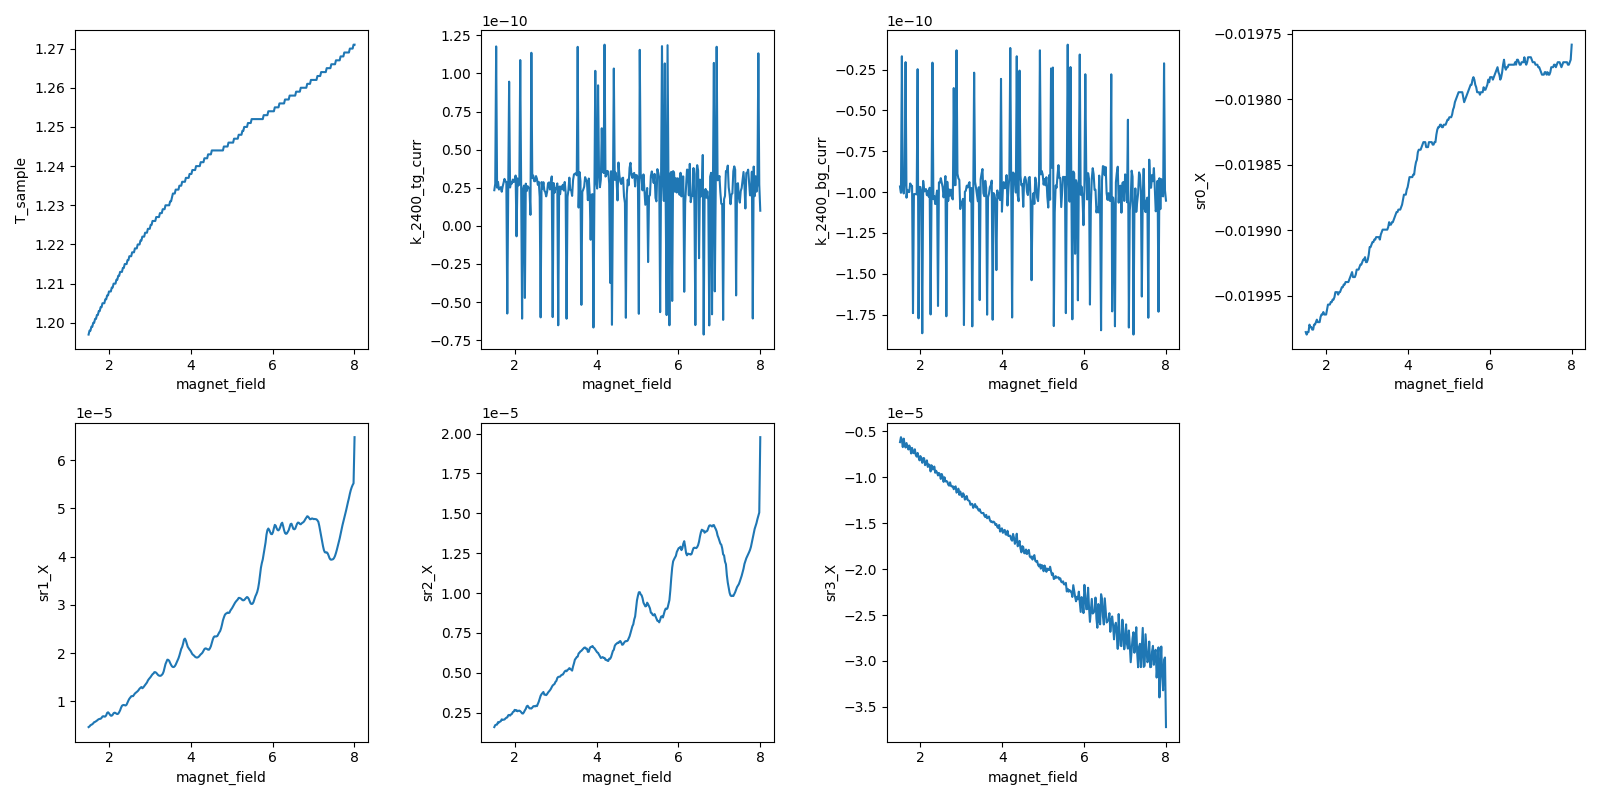

2026-07-18 09:13:36,469 [INFO] Completed in 0h 53m 55s


2026-07-18 09:13:36,470 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\8\data.tsv.gz


rung 0 sweep done (file per rung); B at +1.50 T


rung 1: nominal 6.0 K, hover-accepted at 5.973 K (ranges (1, 1), T_vap 1.72 K)
2026-07-18 09:15:21,505 [INFO] Starting sweep with ID 9


2026-07-18 09:15:21,506 [INFO] Minimum duration 0h 0m 0s


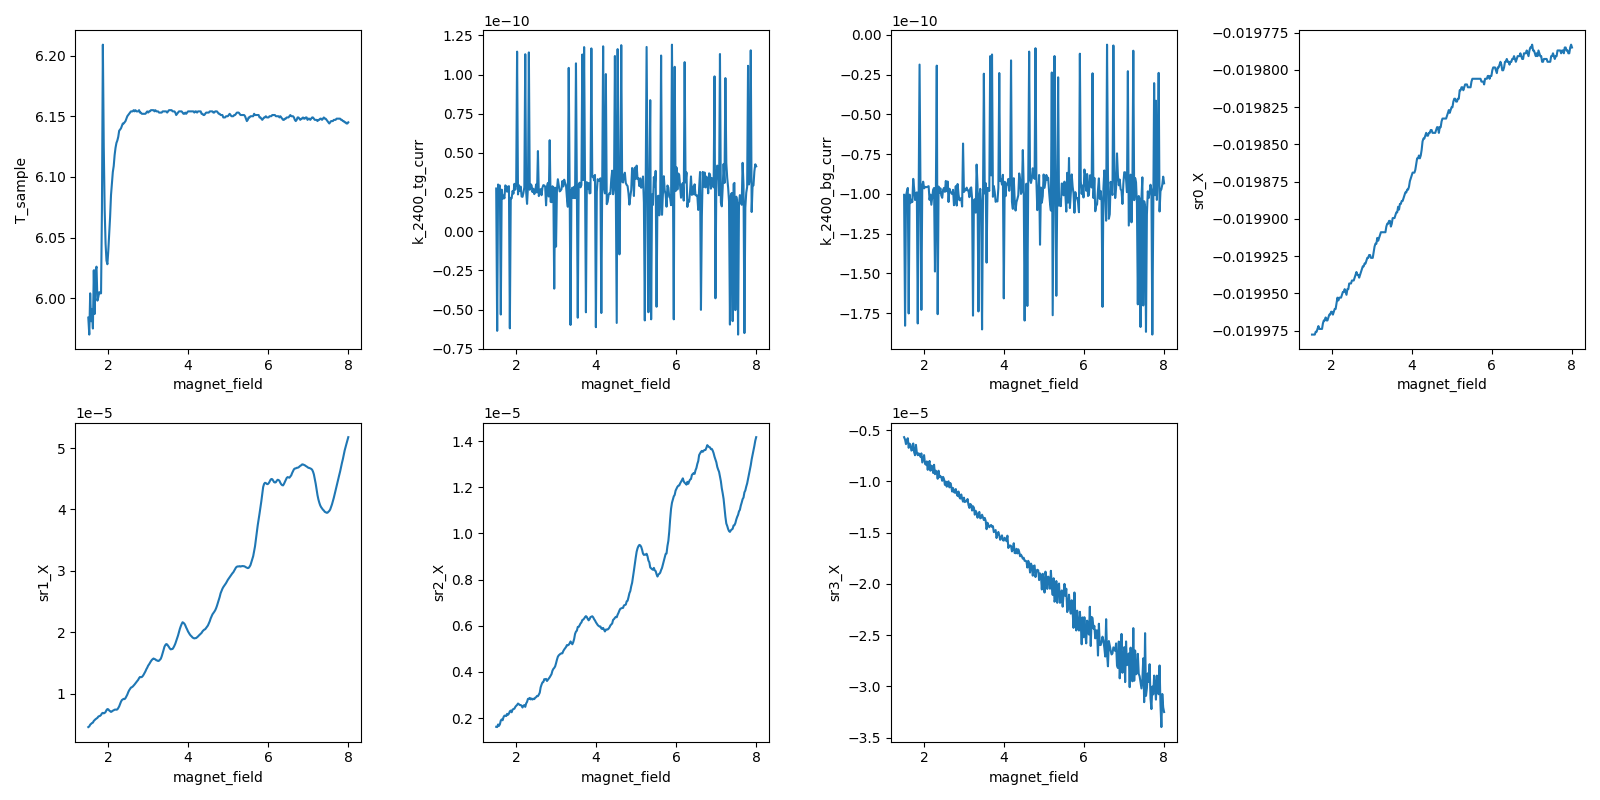

2026-07-18 10:09:17,496 [INFO] Completed in 0h 53m 55s


2026-07-18 10:09:17,497 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\9\data.tsv.gz


rung 1 sweep done (file per rung); B at +8.01 T


rung 2: nominal 10.0 K, hover-accepted at 10.012 K (ranges (1, 1), T_vap 9.49 K)
2026-07-18 10:10:42,565 [INFO] Starting sweep with ID 10


2026-07-18 10:10:42,565 [INFO] Minimum duration 0h 0m 0s


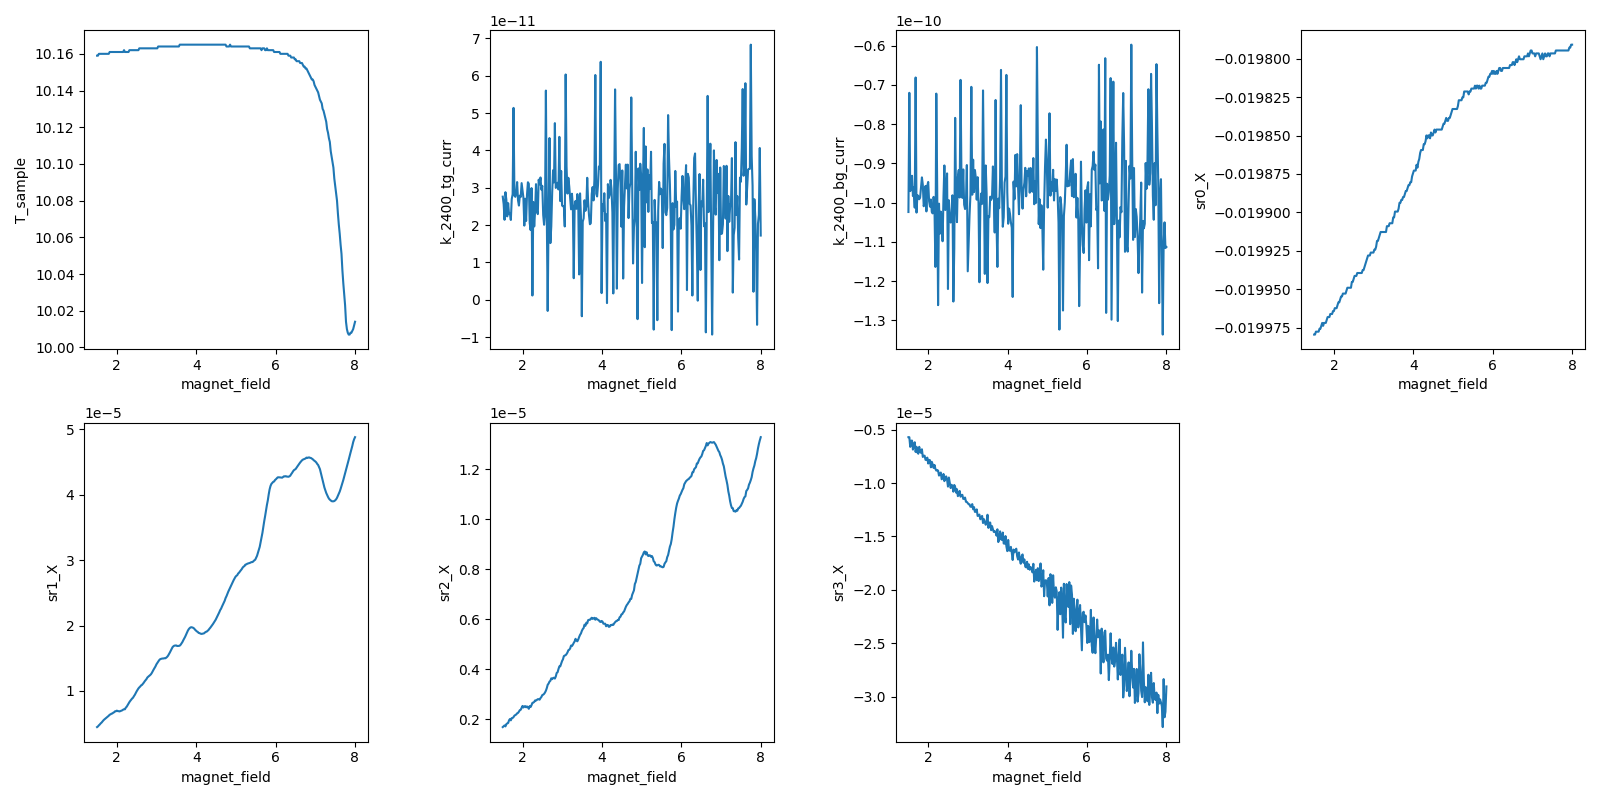

2026-07-18 11:04:38,907 [INFO] Completed in 0h 53m 55s


2026-07-18 11:04:38,909 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\10\data.tsv.gz


rung 2 sweep done (file per rung); B at +1.50 T


rung 3: nominal 15.0 K, hover-accepted at 15.031 K (ranges (1, 1), T_vap 14.25 K)
2026-07-18 11:06:33,950 [INFO] Starting sweep with ID 11


2026-07-18 11:06:33,951 [INFO] Minimum duration 0h 0m 0s


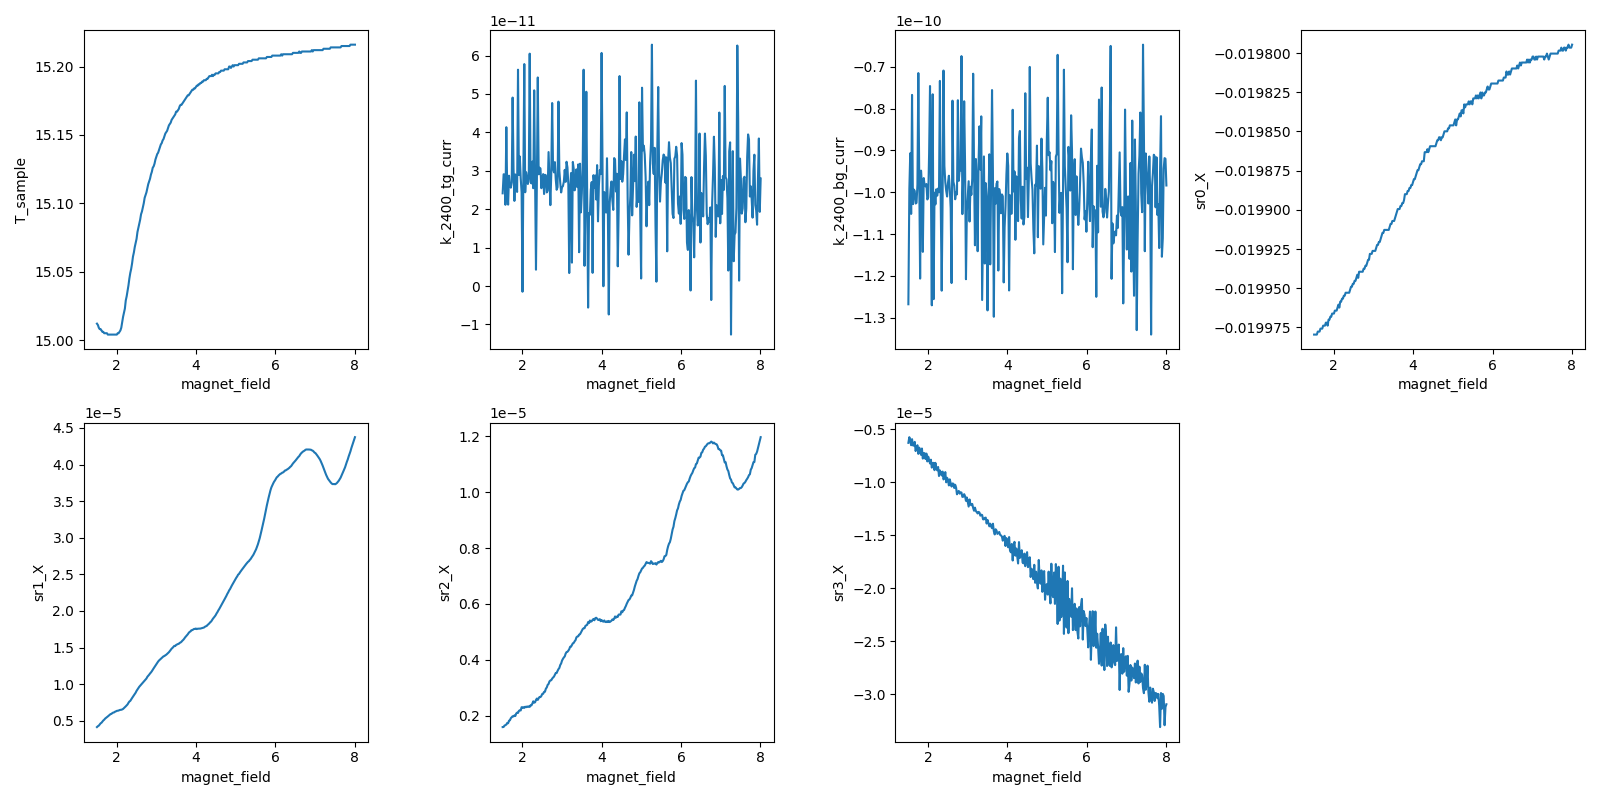

2026-07-18 12:00:31,051 [INFO] Completed in 0h 53m 56s


2026-07-18 12:00:31,052 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\11\data.tsv.gz


rung 3 sweep done (file per rung); B at +8.01 T


rung 4: nominal 22.0 K, hover-accepted at 22.015 K (ranges (2, 2), T_vap 20.90 K)
2026-07-18 12:02:26,079 [INFO] Starting sweep with ID 12


2026-07-18 12:02:26,079 [INFO] Minimum duration 0h 0m 0s


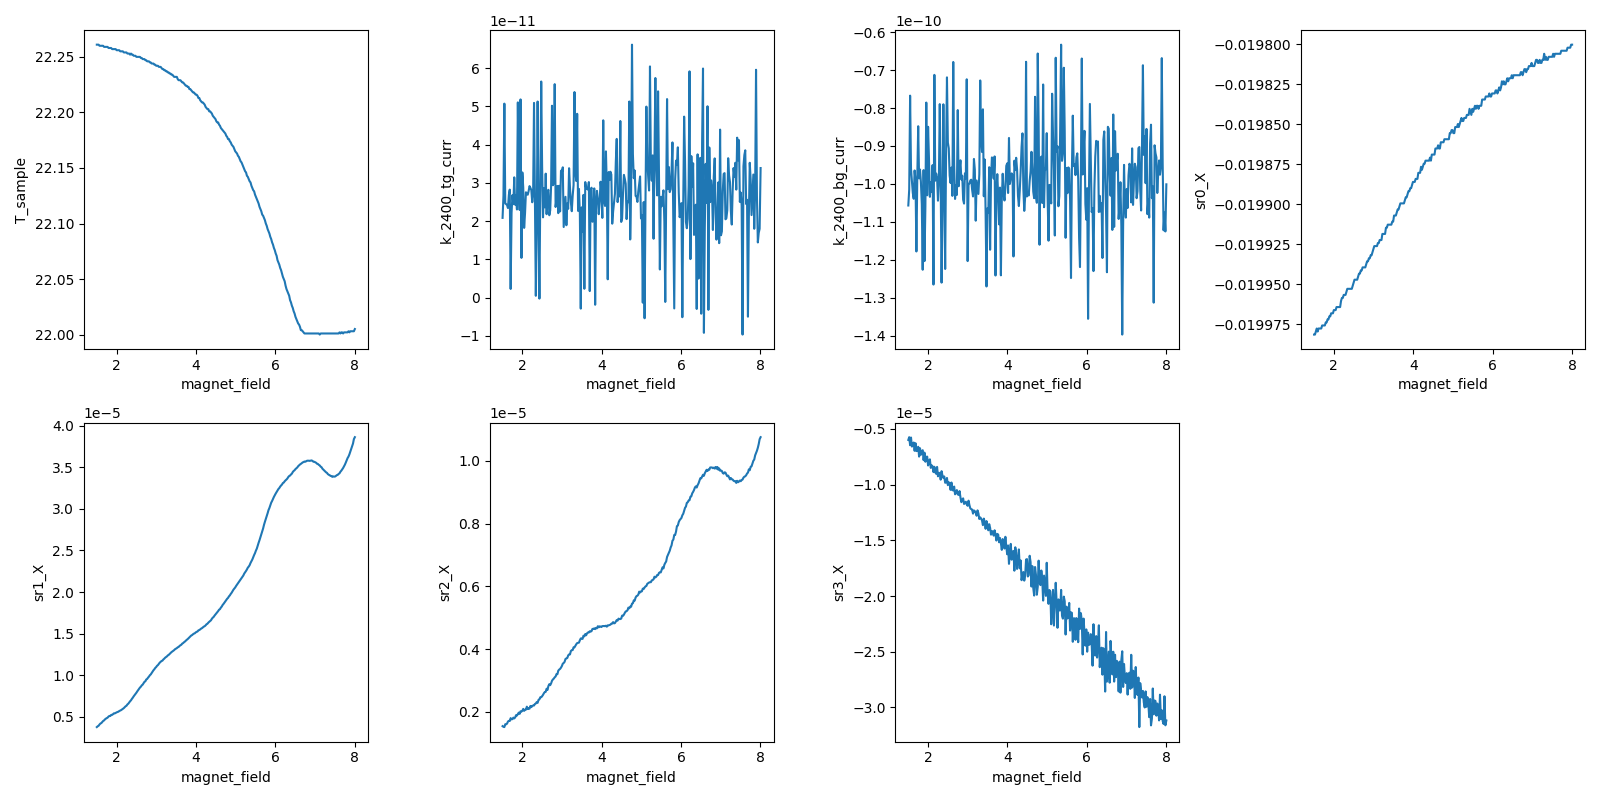

2026-07-18 12:56:22,261 [INFO] Completed in 0h 53m 55s


2026-07-18 12:56:22,261 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\12\data.tsv.gz


rung 4 sweep done (file per rung); B at +1.50 T


rung 5: nominal 32.0 K, hover-accepted at 32.018 K (ranges (2, 2), T_vap 30.40 K)
2026-07-18 12:58:17,320 [INFO] Starting sweep with ID 13


2026-07-18 12:58:17,320 [INFO] Minimum duration 0h 0m 0s


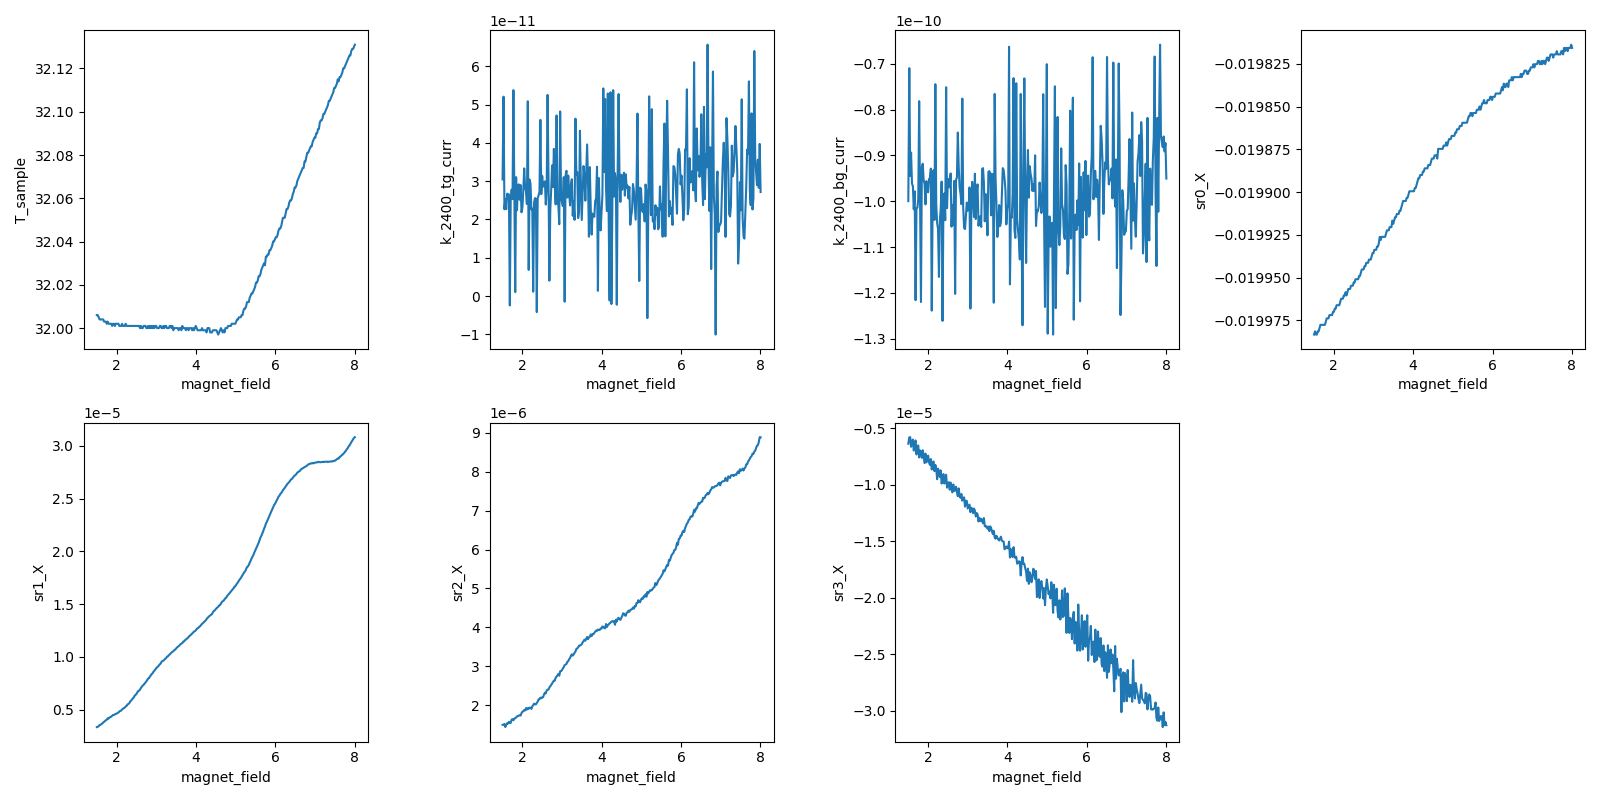

2026-07-18 13:52:14,151 [INFO] Completed in 0h 53m 56s


2026-07-18 13:52:14,152 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260717-QC0426\data\13\data.tsv.gz


rung 5 sweep done (file per rung); B at +8.01 T
ladder complete; heaters off, passive cooldown from ~32.1 K; B at +8.01 T; gates hold the hole spot


In [26]:
# === LK mass ladder (temperature-dependence-vti, Flavor B) ===
# Fixed point: hole n = -3.0e12, D = 0. Same-window field sweep per rung,
# alternating direction (never re-traverse). Per-branch LK masses decide
# the ABA call (two masses + a sum-mass breakdown tone) — investigation Verify.

RUNGS = [None, 6.0, 10.0, 15.0, 22.0, 32.0]   # None = base (no heater); K
B_LK_LO, B_LK_HI = 1.5, 8.0                   # deltaF = 1.85 T — splits 28/33
D_INVB = 1.0 / (3 * 33.2)
DB = D_INVB * B_LK_LO**2                       # 22.6 mT
NPTS = int(np.floor((B_LK_HI - B_LK_LO) / DB)) + 1

# -- preconditions
B = magnet.field()
Ts = T_sample()
print(f"precheck: B={B:+.3f} T (expect ~8, fan end), T={Ts:.3f} K (base)")
assert abs(B - 8.0) < 0.1, f"STOP: field not at 8 T: {B}"
assert Ts < 1.5, f"STOP: not at base: {Ts}"
hr = (heater.sample_range(), heater.vaporizer_range())
print(f"heater ranges at start: {hr} (expect (0, 0))")
assert hr == (0, 0), "STOP: heaters not off at ladder start"

# gates to the hole spot (already characterized; run-4 voltage convention —
# rung labels/gates keep the run-5 operating point for comparability)
vtg_h, vbg_h = gates_for(-3.0, 0.0)
k_2400_tg.volt(vtg_h)
k_2400_bg.volt(vbg_h)
sr1.sensitivity(1e-4)   # run-6 proven at this point to 8 T
sr2.sensitivity(5e-5)
sr3.sensitivity(1e-4)   # headroom for warm-rung R drift
print(f"gates ({vtg_h:+.3f}, {vbg_h:+.3f}); sens sr1 1e-4, sr2 5e-5, sr3 1e-4")

import os
LOGFILE = VTI.temp_logfile_candidates["T_sample"][0]

def fresh_T():
    """Logfile-freshness-guarded T read (>= 2-3 write periods per rig card)."""
    age = time.time() - os.path.getmtime(LOGFILE)
    assert age < 15.0, f"STOP: T logfile stale ({age:.0f} s) — dead worker?"
    return T_sample()

def wait_hover(target, timeout_s=1800):
    """Hover acceptance: spread < 0.1 K over 90 s inside [target-0.5, target+3].
    Direction-aware runaway guard: fault only on T_vap rising > 2 K above both
    its rung-start value and the target."""
    tv0 = T_vaporizer()
    t0 = time.time()
    window = []
    while time.time() - t0 < timeout_s:
        interruptible_sleep(10)
        Tn = fresh_T()
        tv = T_vaporizer()
        if tv > tv0 + 2.0 and tv > target + 2.0:
            heater.off("both")
            raise RuntimeError(f"runaway: T_vap={tv:.2f} K > start+2 and target+2 — heaters off")
        window.append((time.time(), Tn))
        window = [(t, x) for t, x in window if time.time() - t <= 90]
        vals = [x for _, x in window]
        if (len(window) >= 8 and (target - 0.5) <= np.mean(vals) <= (target + 3.0)
                and (max(vals) - min(vals)) < 0.1):
            return np.mean(vals)
    raise RuntimeError(f"hover acceptance timed out at {timeout_s} s (T={fresh_T():.2f} K)")

for ri, rung in enumerate(RUNGS):
    if rung is None:
        T_acc = fresh_T()
        print(f"rung 0: base, T = {T_acc:.3f} K (no heater)")
    else:
        heater.set_both(rung, ratio=0.95)
        interruptible_sleep(5)
        hr = (heater.sample_range(), heater.vaporizer_range())
        assert hr != (0, 0), f"STOP: set_both({rung}) left ranges at 0 — heater not driving"
        T_acc = wait_hover(rung)
        print(f"rung {ri}: nominal {rung} K, hover-accepted at {T_acc:.3f} K "
              f"(ranges {hr}, T_vap {T_vaporizer():.2f} K)")

    # alternate direction from the live field (never re-traverse)
    B_now = magnet.field()
    if abs(B_now - B_LK_HI) < abs(B_now - B_LK_LO):
        B_vec = np.linspace(B_LK_HI, B_LK_LO, NPTS)
    else:
        B_vec = np.linspace(B_LK_LO, B_LK_HI, NPTS)

    meas_config["comments"] = (
        f"temperature-dependence-vti Flavor B (LK mass ladder): rung {ri} "
        f"nominal {'base' if rung is None else rung}, accepted T={T_acc:.3f} K; "
        f"hole n=-3.0e12 D=0 (Vtg={vtg_h:+.3f}, Vbg={vbg_h:+.3f}); "
        f"B {B_vec[0]:.2f}->{B_vec[-1]:.2f} T, dB=22.6 mT; 20 nA @ 13 Hz"
    )
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence-vti')
    s.add_comment(f'LK rung {ri}: T_nom={"base" if rung is None else rung} K, '
                  f'T_acc={T_acc:.3f} K, (Vtg, Vbg) = ({vtg_h:.4f}, {vbg_h:.4f}), n = -3.0, D = 0')
    s.fp(magnet.field)
    s.fp(k_2400_tg.volt).fp(k_2400_tg.curr)
    s.fp(k_2400_bg.volt).fp(k_2400_bg.curr)
    s.fp(T_sample).fp(T_vaporizer)
    s.plot(magnet.field, T_sample)
    s.plot(magnet.field, k_2400_tg.curr)
    s.plot(magnet.field, k_2400_bg.curr)
    for lia in (sr0, sr1, sr2, sr3):
        s.fp(lia.X).fp(lia.P)
        s.plot(magnet.field, lia.X)
    s.sweep(magnet.field, B_vec, delay=0)
    print(f"rung {ri} sweep done (file per rung); B at {magnet.field():+.2f} T")

# ladder done: heaters off, passive descent toward base (no catch — end state)
heater.off("both")
print(f"ladder complete; heaters off, passive cooldown from ~{fresh_T():.1f} K; "
      f"B at {magnet.field():+.2f} T; gates hold the hole spot")


## HERA — session wrap (2026-07-18)

Investigation complete: **QC0426 = ABA (Bernal), strong, per-region** — call + evidence + hedges in the ana notebook (final Step-7 block). Parking gates at 0; magnet left at 8 T (flagged to operator — ramp home is ~58 min if wanted), heaters off and passively descending from 32 K.

In [27]:
# park gates; magnet + heater state readback (session wrap)
k_2400_tg.volt(0)
k_2400_bg.volt(0)
print(f'gates parked: Vtg={k_2400_tg.volt()}, Vbg={k_2400_bg.volt()}, Si={dc205.voltage()} V')
print(f'B={magnet.field():+.3f} T (left at 8 T); heater ranges={heater.sample_range()},{heater.vaporizer_range()} (off)')
print(f'T_sample={T_sample():.2f} K (passive descent), T_vap={T_vaporizer():.2f} K')

gates parked: Vtg=0.0, Vbg=0.0, Si=0.0 V
B=+8.003 T (left at 8 T); heater ranges=0,0 (off)
T_sample=31.92 K (passive descent), T_vap=24.14 K
